# Import dữ liệu

In [44]:

import pandas as pd
import kagglehub
from pathlib import Path

# Dataset 1: Uber
path1 = kagglehub.dataset_download(
    "yashdevladdha/uber-ride-analytics-dashboard"
)

# Dataset 2: Ola
path2 = kagglehub.dataset_download(
    "shayanzk/ola-ride-bookings-dataset"
)

# Hàm đọc file CSV hoặc Excel
def load_data(path):
    files = list(Path(path).rglob("*.csv"))
    files += list(Path(path).rglob("*.xlsx"))

    if not files:
        raise FileNotFoundError("Không tìm thấy CSV hoặc Excel")

    print("Các file tìm thấy:", files)

    file = files[0]

    if file.suffix.lower() == ".csv":
        return pd.read_csv(file, low_memory=False)
    return pd.read_excel(file)

# Đọc và lấy tối đa 1000 bản ghi
df1 = load_data(path1).head(1000).copy()
df2 = load_data(path2).head(1000).copy()

print("Uber:", df1.shape)
print("Ola:", df2.shape)

display(df1.head())
display(df2.head())


Các file tìm thấy: [WindowsPath('C:/Users/TRONG/.cache/kagglehub/datasets/yashdevladdha/uber-ride-analytics-dashboard/versions/2/ncr_ride_bookings.csv')]
Các file tìm thấy: [WindowsPath('C:/Users/TRONG/.cache/kagglehub/datasets/shayanzk/ola-ride-bookings-dataset/versions/1/rideBookings.csv')]
Uber: (1000, 21)
Ola: (1000, 21)


,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


In [45]:
print("Cột Uber:")
print(df1.columns.tolist())

print("\nCột Ola:")
print(df2.columns.tolist())

# Các cột chung
common_cols = df1.columns.intersection(df2.columns)

print("\nCác cột chung:", common_cols.tolist())

Cột Uber:
['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']

Cột Ola:
['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']

Các cột chung: ['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides b

In [46]:
# Kiểm tra cấu trúc dữ liệu
print("Uber:", df1.shape)
print("Ola:", df2.shape)

print(df1.columns.tolist())
print(df2.columns.tolist())

Uber: (1000, 21)
Ola: (1000, 21)
['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']
['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']


In [47]:
# Sao chép dữ liệu
uber = df1.copy()
ola = df2.copy()

# Thêm cột nguồn
uber['Source'] = 'Uber'
ola['Source'] = 'Ola'

# Nối dọc
df_concat = pd.concat(
    [uber, ola],
    axis=0,
    ignore_index=True
)

print(df_concat.shape)
display(df_concat.head())

(2000, 22)


,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method,Source
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Uber
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI,Uber
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card,Uber
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI,Uber
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI,Uber


In [48]:
import numpy as np

# Lấy 1000 chuyến xe có mã duy nhất
df_rides = df1.dropna(
    subset=['Booking ID']
).drop_duplicates(
    subset=['Booking ID']
).head(1000).copy()

# Tạo bảng thanh toán giả lập
rng = np.random.default_rng(42)

df_payments = pd.DataFrame({
    'Booking ID': df_rides['Booking ID'].values,
    'Discount': rng.integers(
        0, 50000, size=len(df_rides)
    ),
    'Payment Status': rng.choice(
        ['Paid', 'Pending', 'Failed'],
        size=len(df_rides)
    )
})

display(df_payments.head())

,Booking ID,Discount,Payment Status
0,"""CNR5884300""",4462,Failed
1,"""CNR1326809""",38697,Failed
2,"""CNR8494506""",32728,Pending
3,"""CNR8906825""",21943,Failed
4,"""CNR1950162""",21650,Paid


In [49]:
df_merge = pd.merge(
    df_rides,
    df_payments,
    on='Booking ID',
    how='inner',
    validate='one_to_one'
)

print(df_merge.shape)
display(df_merge.head())

(1000, 23)


,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method,Discount,Payment Status
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4462,Failed
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI,38697,Failed
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card,32728,Pending
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI,21943,Failed
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI,21650,Paid


In [50]:
print("Uber:", df1.shape)
print("Ola:", df2.shape)

print("Sau concat:", df_concat.shape)
print("Sau merge:", df_merge.shape)

# Kiểm tra giá trị thiếu
print(df_concat.isna().sum())

# Kiểm tra mã đặt xe sau merge
print(df_merge['Booking ID'].duplicated().sum())

Uber: (1000, 21)
Ola: (1000, 21)
Sau concat: (2000, 22)
Sau merge: (1000, 23)
Date                                    0
Time                                    0
Booking ID                              0
Booking Status                          0
Customer ID                             0
Vehicle Type                            0
Pickup Location                         0
Drop Location                           0
Avg VTAT                              128
Avg CTAT                              616
Cancelled Rides by Customer          1864
Reason for cancelling by Customer    1864
Cancelled Rides by Driver            1648
Driver Cancellation Reason           1648
Incomplete Rides                     1882
Incomplete Rides Reason              1882
Booking Value                         616
Ride Distance                         616
Driver Ratings                        734
Customer Rating                       734
Payment Method                        616
Source                                  

# EDA - PHÂN TÍCH DỮ LIỆU KHÁM PHÁ

Trong notebook hiện tại, df_merge là bảng Uber đã ghép với dữ liệu thanh toán giả lập. Phần dưới đây kiểm tra dữ liệu thiếu trên bảng này, giữ nguyên dữ liệu gốc và tạo df_clean để dùng cho các bước EDA tiếp theo.

In [51]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
df_eda = df_merge.copy()

print("Kích thước dữ liệu:", df_eda.shape)

# Thống kê dữ liệu thiếu theo từng cột
missing_report = pd.DataFrame({
    "Missing_Count": df_eda.isna().sum(),
    "Missing_Percent": (df_eda.isna().mean() * 100).round(2)
})
missing_report = missing_report.sort_values(
    by="Missing_Percent", ascending=False
)
print(missing_report)

Kích thước dữ liệu: (1000, 23)
                                   Missing_Count  Missing_Percent
Incomplete Rides                             941             94.1
Incomplete Rides Reason                      941             94.1
Reason for cancelling by Customer            932             93.2
Cancelled Rides by Customer                  932             93.2
Cancelled Rides by Driver                    824             82.4
Driver Cancellation Reason                   824             82.4
Customer Rating                              367             36.7
Driver Ratings                               367             36.7
Payment Method                               308             30.8
Ride Distance                                308             30.8
Booking Value                                308             30.8
Avg CTAT                                     308             30.8
Avg VTAT                                      64              6.4
Discount                                     

# Xử lý dữ liệu thiếu
- Với cột số: điền bằng median (trung vị) để hạn chế ảnh hưởng của các giá trị quá lớn hoặc quá nhỏ.
- Với cột phân loại/chuỗi: điền bằng mode (giá trị xuất hiện nhiều nhất); nếu cả cột đều thiếu thì dùng Unknown.
- Không xóa hàng loạt các dòng bị thiếu. Những cột mang ý nghĩa đặc biệt, chẳng hạn lý do hủy chuyến, cần xem xét ngữ cảnh nghiệp vụ trước khi quyết định cách điền.

In [53]:
# Lọc lại dữ liệu
df_clean = df_eda.copy()

numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()
categorical_cols = df_clean.select_dtypes(exclude="number").columns.tolist()

# Điền dữ liệu thiếu ở cột số bằng median
for col in numeric_cols:
    if df_clean[col].isna().any():
        median_value = df_clean[col].median()
        if pd.notna(median_value):
            df_clean[col] = df_clean[col].fillna(median_value)

# Điền dữ liệu thiếu ở cột phân loại bằng mode; nếu không có mode thì dùng Unknown
for col in categorical_cols:
    if df_clean[col].isna().any():
        mode_values = df_clean[col].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        df_clean[col] = df_clean[col].fillna(fill_value)

after_report = pd.DataFrame({
    "Missing_Count_Before": df_eda.isna().sum(),
    "Missing_Count_After": df_clean.isna().sum(),
    "Missing_Percent_After": (df_clean.isna().mean() * 100).round(2)
})

print("So sánh dữ liệu thiếu trước và sau xử lý:")
print(after_report)
print("Tổng số ô thiếu sau xử lý:", int(df_clean.isna().sum().sum()))
print("Kích thước trước xử lý:", df_eda.shape)
print("Kích thước sau xử lý:", df_clean.shape)

So sánh dữ liệu thiếu trước và sau xử lý:
                                   Missing_Count_Before  Missing_Count_After  \
Date                                                  0                    0   
Time                                                  0                    0   
Booking ID                                            0                    0   
Booking Status                                        0                    0   
Customer ID                                           0                    0   
Vehicle Type                                          0                    0   
Pickup Location                                       0                    0   
Drop Location                                         0                    0   
Avg VTAT                                             64                    0   
Avg CTAT                                            308                    0   
Cancelled Rides by Customer                         932                    0  

### Kết luận: 
Dữ liệu ban đầu có kích thước (1000, 23) và nhiều cột bị thiếu dữ liệu, trong đó một số cột có tỷ lệ thiếu trên 90%. Sau khi xử lý, tổng số ô thiếu giảm về 0, kích thước dữ liệu vẫn giữ nguyên. Tuy nhiên, cần lựa chọn phương pháp xử lý phù hợp với từng loại dữ liệu để tránh làm sai lệch kết quả phân tích.

# Phân tích đơn biến (Univariate Analysis)

Phân tích từng cột riêng lẻ.
- Cột số: mean, median, standard deviation, skewness, kurtosis, phân phối và ngoại lệ.
- Cột phân loại: tần suất và tỷ lệ phần trăm.

In [54]:
# Lọc dữ liệu số để phân tích
numeric_cols = df_clean.select_dtypes(include="number").columns

df_clean[numeric_cols].describe()

stats = df_clean[numeric_cols].agg(
    ["mean", "median", "skew", "kurt"]
).T

print(stats)

                                    mean   median      skew       kurt
Avg VTAT                         8.30730      8.1  0.296180  -0.470879
Avg CTAT                        28.48770     28.2  0.228906  -0.297930
Cancelled Rides by Customer      1.00000      1.0  0.000000   0.000000
Cancelled Rides by Driver        1.00000      1.0  0.000000   0.000000
Incomplete Rides                 1.00000      1.0  0.000000   0.000000
Booking Value                  457.75200    400.0  2.491568  10.946392
Ride Distance                   25.16521     24.5  0.162939  -0.491886
Driver Ratings                   4.25230      4.3 -1.029169   2.227062
Customer Rating                  4.43970      4.5 -1.446074   3.310477
Discount                     25149.78700  25298.0 -0.030525  -1.208631


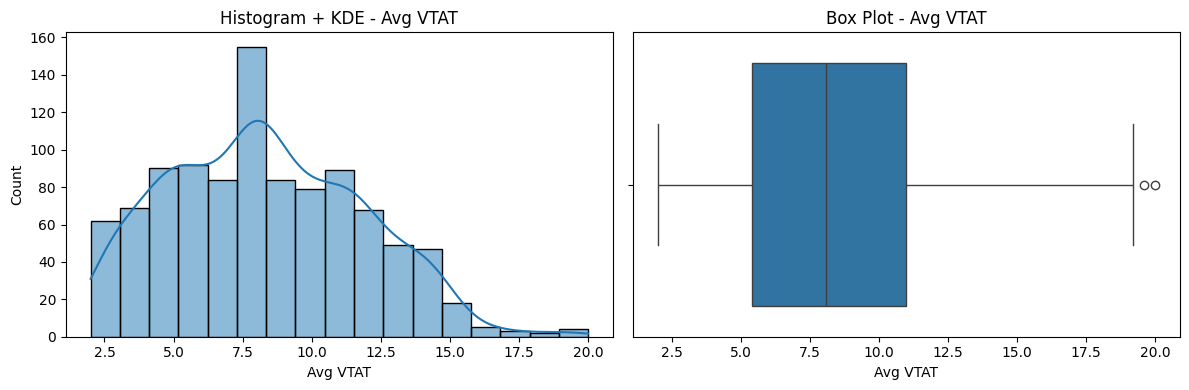

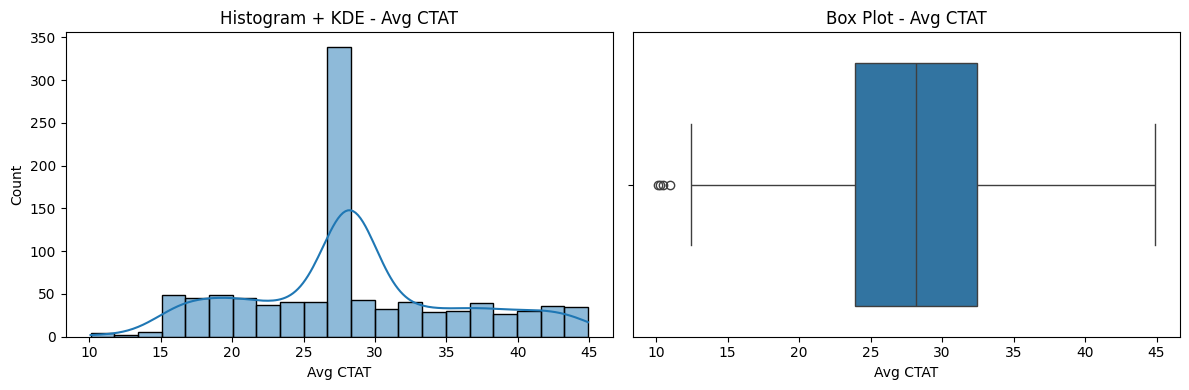

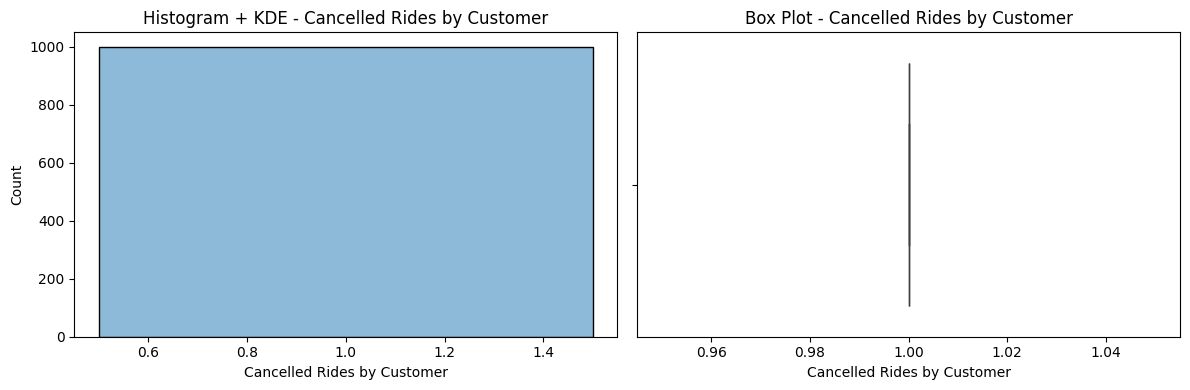

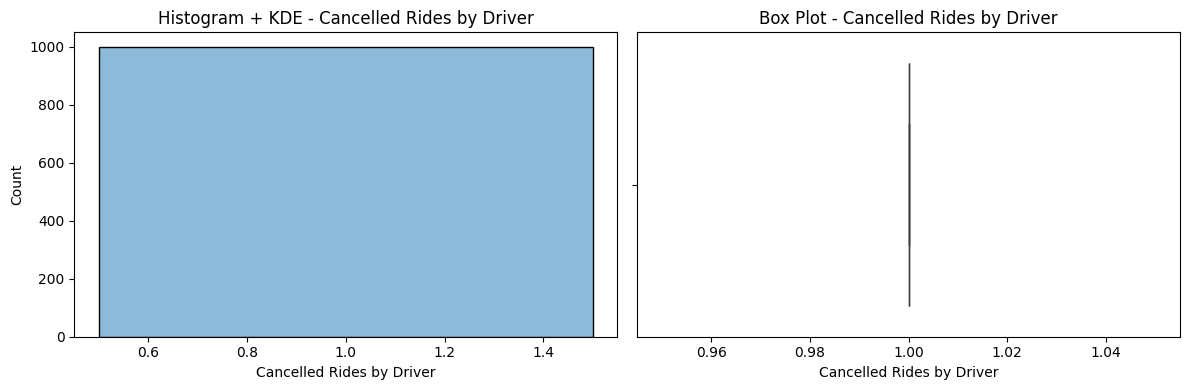

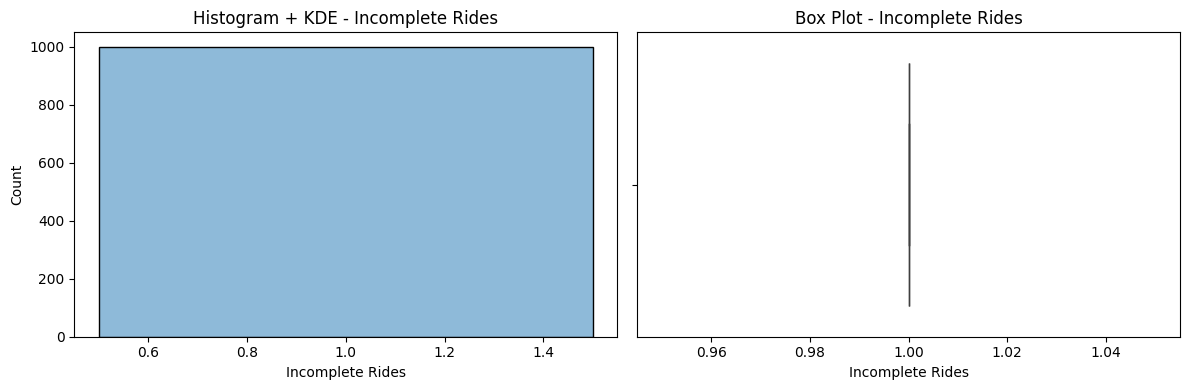

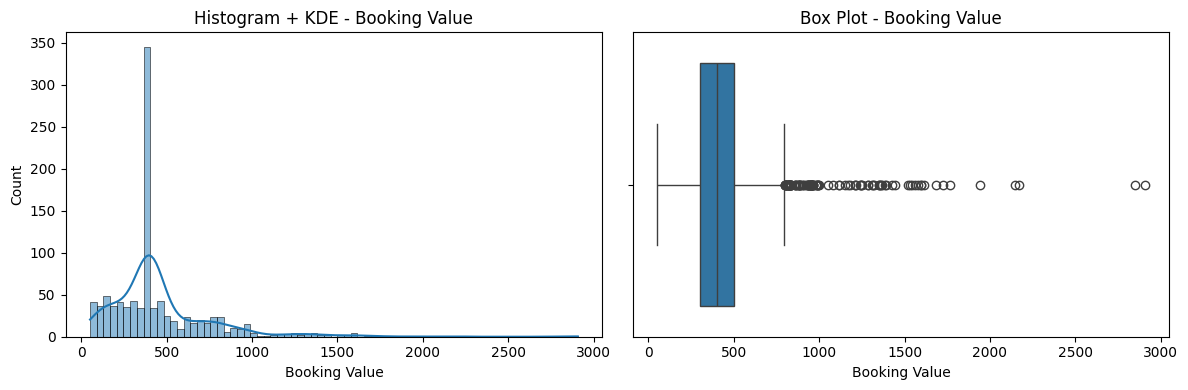

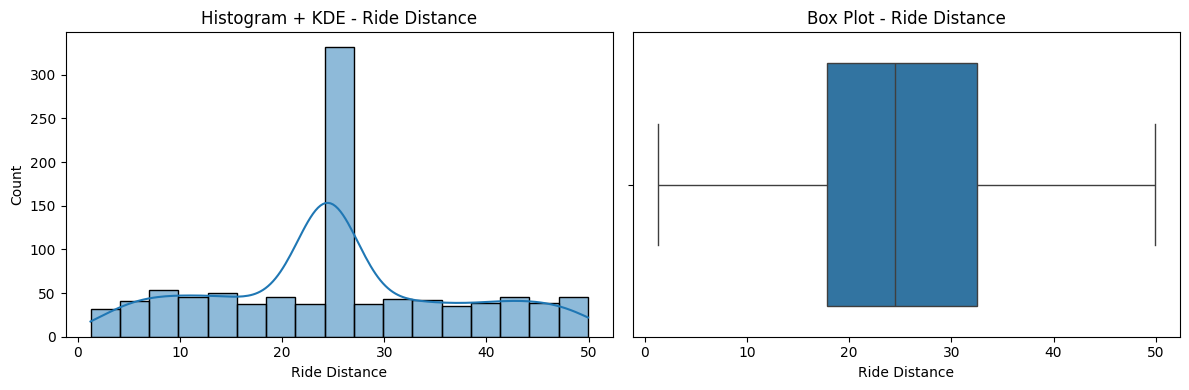

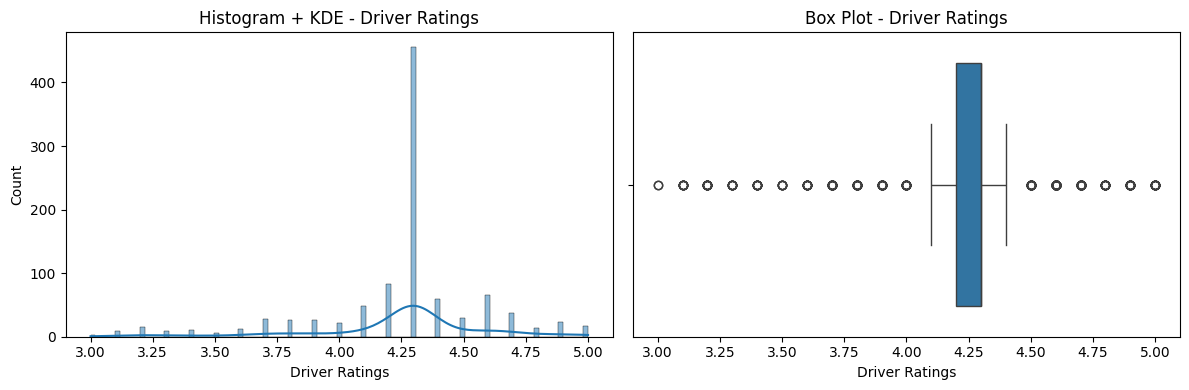

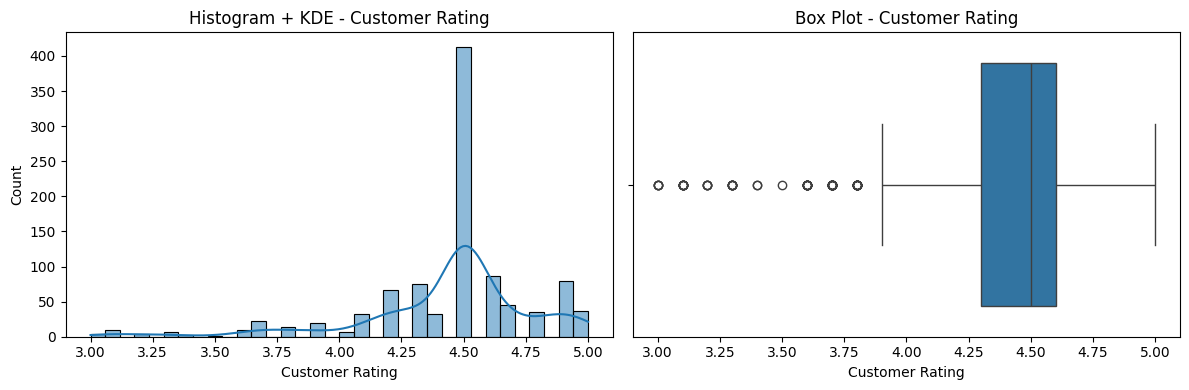

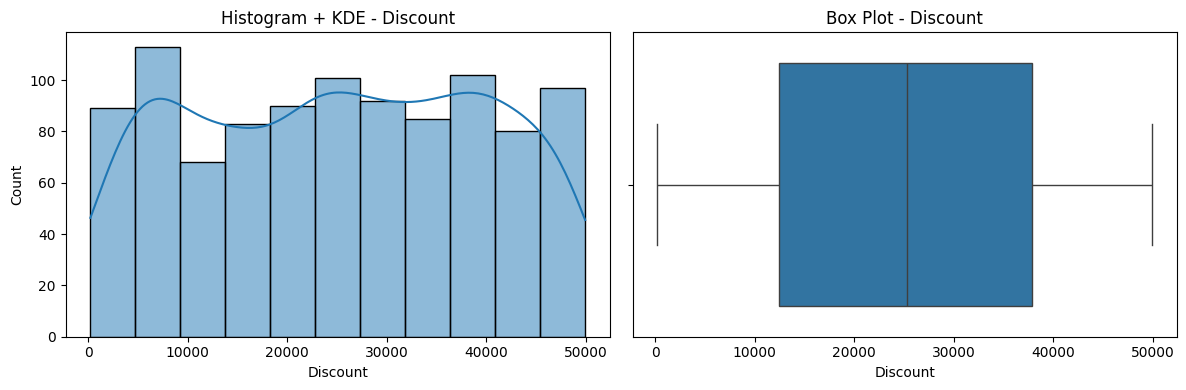

In [55]:
for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(df_clean[col].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"Histogram + KDE - {col}")

    sns.boxplot(x=df_clean[col], ax=axes[1])
    axes[1].set_title(f"Box Plot - {col}")

    plt.tight_layout()
    plt.show()

## Thống kê các cột phân loại

In [56]:
categorical_cols = [
    "Booking Status",
    "Vehicle Type",
    "Payment Method",
    "Payment Status",
    "Pickup Location",
    "Drop Location"
]

for col in categorical_cols:
    print(f"\n===== {col} =====")
    print("Tần suất:")
    print(df_clean[col].value_counts())

    print("\nTỷ lệ phần trăm (%):")
    print(df_clean[col].value_counts(normalize=True).mul(100).round(2))


===== Booking Status =====
Tần suất:
Booking Status
Completed                633
Cancelled by Driver      176
Cancelled by Customer     68
No Driver Found           64
Incomplete                59
Name: count, dtype: int64

Tỷ lệ phần trăm (%):
Booking Status
Completed                63.3
Cancelled by Driver      17.6
Cancelled by Customer     6.8
No Driver Found           6.4
Incomplete                5.9
Name: proportion, dtype: float64

===== Vehicle Type =====
Tần suất:
Vehicle Type
Auto             266
Go Mini          187
Go Sedan         184
Bike             146
Premier Sedan    132
eBike             61
Uber XL           24
Name: count, dtype: int64

Tỷ lệ phần trăm (%):
Vehicle Type
Auto             26.6
Go Mini          18.7
Go Sedan         18.4
Bike             14.6
Premier Sedan    13.2
eBike             6.1
Uber XL           2.4
Name: proportion, dtype: float64

===== Payment Method =====
Tần suất:
Payment Method
UPI            632
Cash           171
Uber Wallet     86
Cr

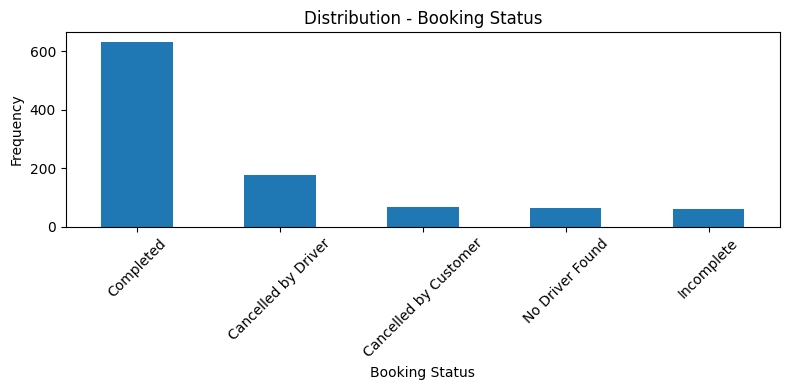

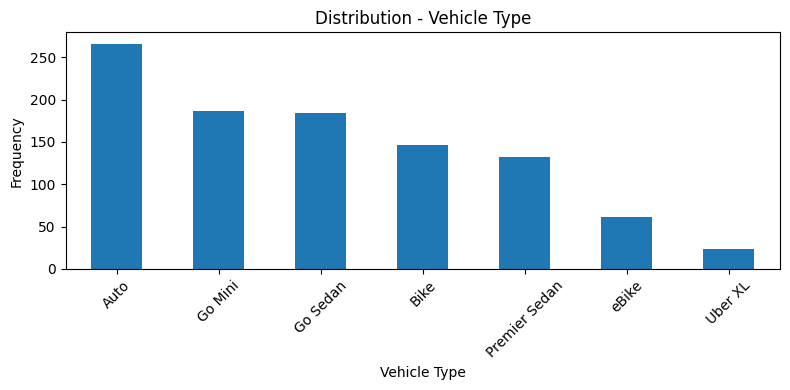

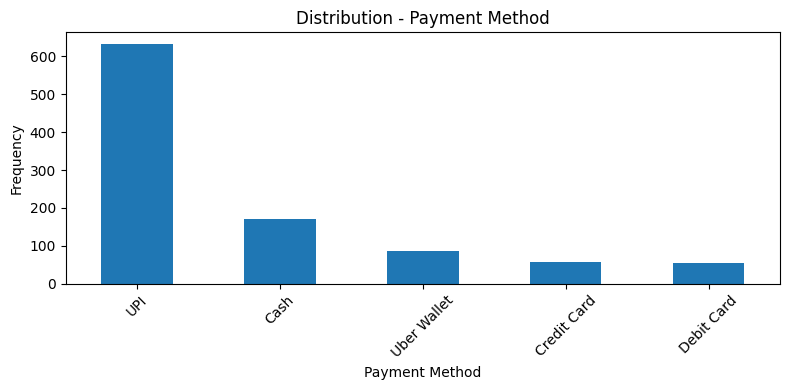

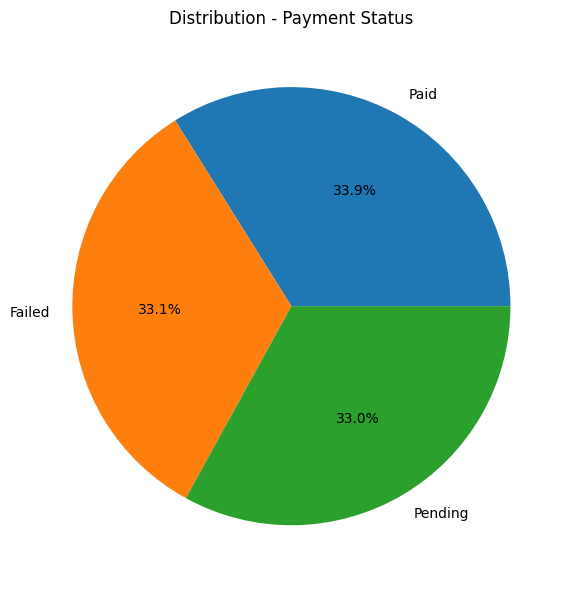

In [57]:
# Chọn các cột phân loại cần vẽ
categorical_cols = [
    "Booking Status",
    "Vehicle Type",
    "Payment Method",
    "Payment Status"
]

for col in categorical_cols:
    counts = df_clean[col].value_counts()

    # Nếu có dưới 5 nhóm thì vẽ biểu đồ tròn
    if len(counts) < 5:
        counts.plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6))
        plt.ylabel("")

    # Nếu có từ 5 nhóm trở lên thì vẽ biểu đồ cột
    else:
        counts.plot(kind="bar", figsize=(8, 4))
        plt.ylabel("Frequency")
        plt.xticks(rotation=45)

    plt.title(f"Distribution - {col}")
    plt.tight_layout()
    plt.show()

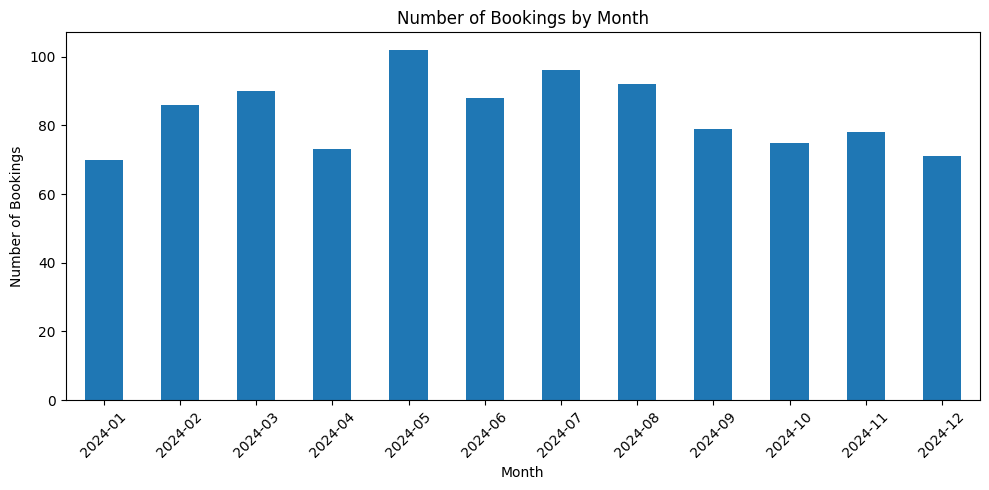

In [58]:
# Chuyển Date sang kiểu ngày tháng
df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")

# Đếm số lượt đặt xe theo từng tháng
monthly_counts = df_clean.groupby(
    df_clean["Date"].dt.to_period("M")
).size()

# Vẽ biểu đồ
monthly_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Number of Bookings by Month")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Nhận xét các biến số
- Avg VTAT, Avg CTAT và Ride Distance: Phân phối tương đối cân đối, ít lệch.
- Booking Value: Phân phối lệch phải rõ rệt, có thể có một số giá trị rất cao.
- Driver Ratings và Customer Rating: Điểm đánh giá tập trung ở mức cao, phân phối lệch trái.
- Discount: Phân phối tương đối đối xứng.
- Các cột hủy chuyến và chuyến không hoàn thành: Không có biến thiên, cần kiểm tra lại dữ liệu.
- Booking Status: Chuyến hoàn thành chiếm tỷ lệ lớn nhất.
- Vehicle Type: Auto là loại xe phổ biến nhất.
- Payment Method: UPI là phương thức thanh toán phổ biến nhất.
- Payment Status: Ba trạng thái Paid, Failed và Pending có tỷ lệ gần tương đương.
- Pickup Location và Drop Location: Địa điểm đón và trả phân bố ở nhiều nơi khác nhau.
- Date: Nên quan sát biểu đồ theo tháng để nhận xét xu hướng số lượt đặt xe theo thời gian.

In [59]:
df_number = df_clean.select_dtypes(include="number").copy()
df_number.head()

,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Cancelled Rides by Driver,Incomplete Rides,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Discount
0,8.1,28.2,1.0,1.0,1.0,400.0,24.50,4.3,4.5,4462
1,4.9,14.0,1.0,1.0,1.0,237.0,5.73,4.3,4.5,38697
2,13.4,25.8,1.0,1.0,1.0,627.0,13.58,4.9,4.9,32728
3,13.1,28.5,1.0,1.0,1.0,416.0,34.02,4.6,5.0,21943
4,5.3,19.6,1.0,1.0,1.0,737.0,48.21,4.1,4.3,21650


In [60]:
df_corr_ready = df_number.loc[:, df_number.nunique() > 1].copy()

df_corr = df_corr_ready.corr()

df_corr.head()

,Avg VTAT,Avg CTAT,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Discount
Avg VTAT,1.000000,0.008576,-0.016057,-0.007946,-0.025628,-0.005616,-0.018423
Avg CTAT,0.008576,1.000000,-0.030954,0.134924,0.050480,-0.040358,-0.026790
Booking Value,-0.016057,-0.030954,1.000000,0.035466,0.024987,-0.051599,-0.019209
Ride Distance,-0.007946,0.134924,0.035466,1.000000,-0.043017,-0.055619,-0.000819
Driver Ratings,-0.025628,0.050480,0.024987,-0.043017,1.000000,0.017591,0.016195


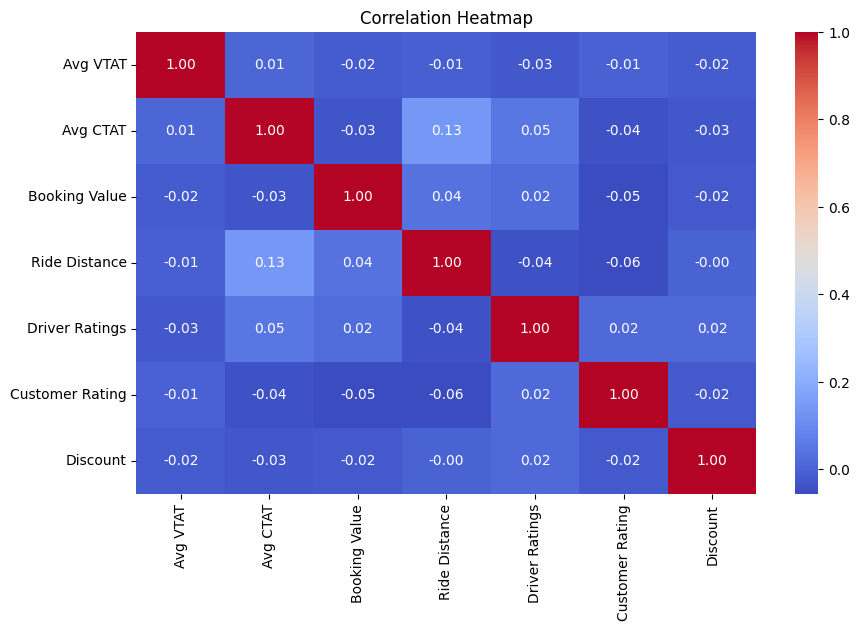

In [61]:
plt.figure(figsize=(10,6))
sns.heatmap(
    df_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
)   

plt.title("Correlation Heatmap")
plt.show()

**KẾT LUẬN:** Dựa trên biểu đồ Heatmap, có thể thấy các biến trong bộ dữ liệu hầu như không có mối tương quan tuyến tính đáng kể với nhau, vì phần lớn hệ số tương quan Pearson đều nằm gần 0.
- Avg CTAT và Ride Distance: Có hệ số tương quan dương cao nhất (r = 0.13), cho thấy khoảng cách chuyến đi tăng thì thời gian hoàn thành chuyến có xu hướng tăng nhẹ. Tuy nhiên, mối tương quan này rất yếu.
- Booking Value và Ride Distance: Hệ số tương quan r = 0.04, gần như không có mối tương quan tuyến tính, cho thấy giá trị đặt xe không có quan hệ tuyến tính rõ ràng với khoảng cách di chuyển trong dữ liệu.
- Driver Ratings và Customer Rating: Hệ số tương quan r = 0.02, cho thấy đánh giá của tài xế và khách hàng gần như không có mối liên hệ tuyến tính.
- Discount: Có hệ số tương quan gần 0 với tất cả các biến khác, cho thấy không có mối quan hệ tuyến tính đáng kể. Tuy nhiên, cần xác minh cột Discount thực sự biểu thị giá trị giảm giá hay chỉ là mã định danh.

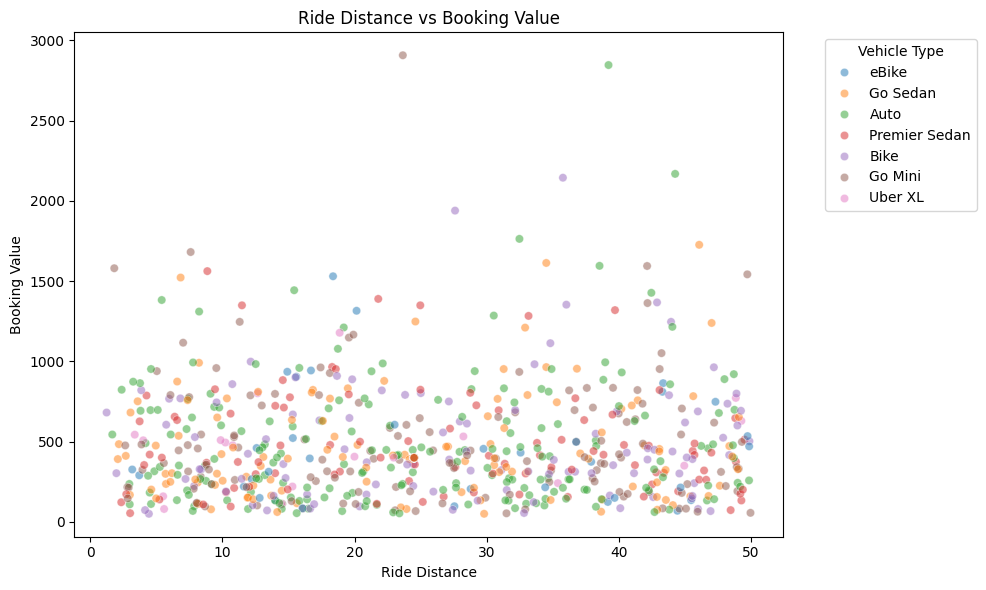

In [62]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Ride Distance",
    y="Booking Value",
    hue="Vehicle Type",
    alpha=0.5
)

plt.title("Ride Distance vs Booking Value")
plt.xlabel("Ride Distance")
plt.ylabel("Booking Value")
plt.legend(title="Vehicle Type", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

**KẾT LUẬN:**
Biểu đồ Scatter Plot cho thấy Ride Distance và Booking Value có mối tương quan tuyến tính rất yếu (Pearson r ≈ 0.04). Các điểm dữ liệu phân bố rải rác, không hình thành xu hướng tăng hoặc giảm rõ ràng. Một số chuyến có giá trị đặt xe cao bất thường, gần 3.000, dù khoảng cách không quá lớn.

So What? Khoảng cách di chuyển không giải thích tốt sự biến động của giá trị đặt xe khi xét riêng lẻ. Giá trị đặt xe có thể còn phụ thuộc vào loại phương tiện và các yếu tố khác.

Ảnh hưởng đến mô hình AI: Không nên chỉ sử dụng Ride Distance để dự đoán Booking Value. Có thể kết hợp thêm Vehicle Type và thử các mô hình hồi quy như Random Forest để đánh giá những mối quan hệ phi tuyến.

Booking Status,Cancelled by Customer,Cancelled by Driver,Completed,Incomplete,No Driver Found
Vehicle Type,,,,,
Auto,4.89,16.54,66.17,6.02,6.39
Bike,8.22,15.07,65.07,6.16,5.48
Go Mini,7.49,16.58,63.10,8.02,4.81
Go Sedan,8.15,20.11,59.24,3.80,8.70
Premier Sedan,6.82,17.42,66.67,5.30,3.79
Uber XL,4.17,12.50,66.67,8.33,8.33
eBike,6.56,26.23,50.82,4.92,11.48


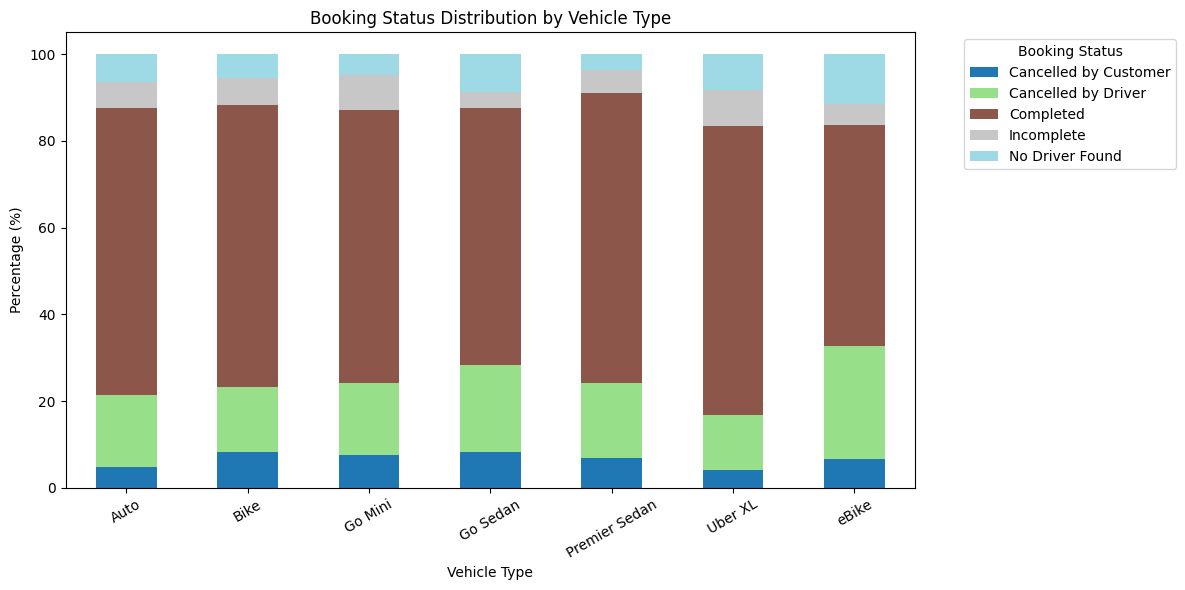

In [63]:
# Tạo bảng chéo
status_table = pd.crosstab(
    df_clean["Vehicle Type"],
    df_clean["Booking Status"],
    normalize="index"
) * 100

display(status_table.round(2))

# Vẽ biểu đồ
ax = status_table.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20"
)

plt.title("Booking Status Distribution by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30)
plt.legend(title="Booking Status", bbox_to_anchor=(1.05, 1))
plt.tight_layout()

**KẾT LUẬN:** 
Biểu đồ cho thấy tỷ lệ hoàn thành chuyến (Completed) chiếm cao nhất ở hầu hết các loại xe, dao động từ 50,82% đến 66,67%. Premier Sedan và Uber XL có tỷ lệ hoàn thành cao nhất (66,67%), trong khi eBike thấp nhất (50,82%) và có tỷ lệ tài xế hủy chuyến cao nhất (26,23%).

So What? eBike có tỷ lệ hủy chuyến và không tìm được tài xế tương đối cao, cho thấy khả năng đáp ứng chuyến đi của loại xe này cần được xem xét.

Ảnh hưởng đến mô hình AI: Có thể sử dụng Vehicle Type làm biến đầu vào cho mô hình phân loại dự đoán Booking Status. Cần chú ý sự chênh lệch tỷ lệ giữa các trạng thái khi huấn luyện và đánh giá mô hình.

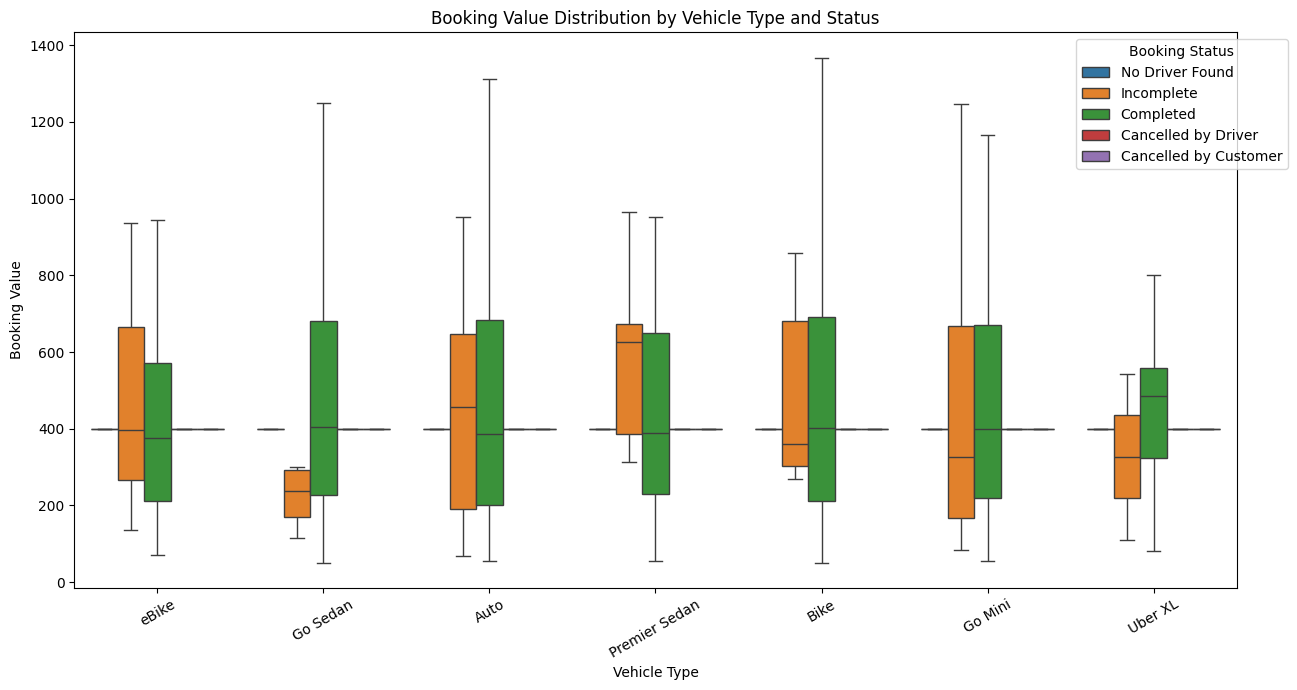

In [64]:
plt.figure(figsize=(13, 7))

sns.boxplot(
    data=df_clean,
    x="Vehicle Type",
    y="Booking Value",
    hue="Booking Status",
    showfliers=False
)

plt.title("Booking Value Distribution by Vehicle Type and Status")
plt.xlabel("Vehicle Type")
plt.ylabel("Booking Value")
plt.xticks(rotation=30)
plt.legend(title="Booking Status", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

KẾT LUẬN: Booking Value Distribution by Vehicle Type and Status
1. Nhận xét biểu đồ
- Giá trị đặt xe (Booking Value) có sự phân bố khác nhau giữa các loại phương tiện và trạng thái chuyến đi.
- Các chuyến Completed có khoảng giá trị đặt xe khá rộng, đặc biệt ở Go Sedan, Auto, Bike và Go Mini. Trung vị của phần lớn nhóm này dao động quanh mức 390–400, riêng Uber XL cao hơn, khoảng 480.
- Nhóm Incomplete có sự khác biệt về trung vị giữa các loại xe. Chẳng hạn, Premier Sedan có trung vị khoảng 630, trong khi Go Sedan chỉ khoảng 240.
- Các nhóm No Driver Found, Cancelled by Driver và Cancelled by Customer có giá trị tập trung gần mức 400, gần như không có độ phân tán trên biểu đồ.
- Các hộp của nhóm Completed và Incomplete có độ rộng đáng kể, cho thấy giá trị đặt xe biến động tương đối lớn trong những nhóm này.
2. So What? – Kết quả có ý nghĩa gì?
Biểu đồ cho thấy loại phương tiện và trạng thái chuyến đi có thể liên quan đến sự khác biệt trong phân phối giá trị đặt xe.

Đáng chú ý, việc các trạng thái không hoàn thành hoặc bị hủy có giá trị gần như cố định ở mức 400 có thể xuất phát từ quá trình xử lý dữ liệu thiếu bằng Median, thay vì phản ánh giá trị thực tế.

Vì vậy, cần phân biệt giá trị quan sát ban đầu với giá trị được điền thay thế để tránh đưa ra kết luận sai lệch về hành vi đặt xe.
3. Ảnh hưởng đến việc lựa chọn mô hình AI
- Regression (Hồi quy): Có thể sử dụng Vehicle Type để dự đoán Booking Value, đồng thời xem xét Ride Distance và các biến phù hợp khác. Nên thử Random Forest Regressor hoặc các mô hình hồi quy khác để đánh giá khả năng nắm bắt quan hệ phi tuyến.
- Classification (Phân loại): Có thể sử dụng Booking Value và Vehicle Type làm biến đầu vào để nghiên cứu khả năng dự đoán Booking Status, nhưng cần kiểm tra thời điểm các biến được ghi nhận nhằm tránh rò rỉ dữ liệu.
- Data Preprocessing: Cần kiểm tra các giá trị Booking Value = 400 xuất hiện ở những trạng thái bị hủy hoặc không tìm được tài xế, vì việc điền Median có thể khiến mô hình học những quy luật không thực sự tồn tại.

# STAGE 2

# HỌC CÓ GIÁM SÁT: REGRESSION 

**Bài toán:** Dự đoán `Booking Value` từ `Ride Distance` và `Vehicle Type`.

**Quy trình:** Lọc nhãn hợp lệ → train/test (80/20) → tiền xử lý riêng trên train → Linear Regression & Decision Tree → MSE, RMSE, R² → Residual Plot → so sánh.

**Lưu ý về dữ liệu:** Không sử dụng `df_clean` đã điền thiếu `Booking Value` bằng median vì biến mục tiêu không nên tạo giả. `df_eda` vẫn giữ nhãn gốc. `Discount` và `Payment Status` là dữ liệu mô phỏng trong bước merge, nên không dùng làm feature. Chỉ chọn các trường có thể biết trước hoặc tại thời điểm báo giá chuyến đi.

In [65]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

assert 'df_eda' in globals()
target = 'Booking Value'
features = ['Ride Distance', 'Vehicle Type']
df_reg = df_eda[features + [target]].copy()
for col in ['Ride Distance', target]:
    df_reg[col] = pd.to_numeric(df_reg[col], errors='coerce')
df_reg = df_reg.dropna(subset=[target])

print('Số quan sát có Booking Value thực tế:', len(df_reg))
print('Số nhãn thiếu trong dữ liệu gốc:', df_eda[target].isna().sum())
print(df_reg[features + [target]].describe(include='all'))
assert len(df_reg) >= 10, 'Không đủ quan sát có nhãn để chia train/test.'


Số quan sát có Booking Value thực tế: 692
Số nhãn thiếu trong dữ liệu gốc: 308
        Ride Distance Vehicle Type  Booking Value
count      692.000000          692     692.000000
unique            NaN            7            NaN
top               NaN         Auto            NaN
freq              NaN          192            NaN
mean        25.461286          NaN     483.456647
std         14.225205          NaN     370.314861
min          1.240000          NaN      51.000000
25%         12.752500          NaN     215.750000
50%         24.500000          NaN     400.000000
75%         38.242500          NaN     671.250000
max         49.950000          NaN    2908.000000


## 1. Chia train/test và tiền xử lý
- Chia 80% train, 20% test với `random_state=42`.
- `Ride Distance`: điền median và chuẩn hóa bằng `StandardScaler`.
- `Vehicle Type`: điền mode, sau đó mã hóa One-Hot.
- Các bước tiền xử lý đều được **fit trên train**, tránh rò rỉ thông tin từ test.

In [66]:
X = df_reg[features]
y = df_reg[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocess = ColumnTransformer([
    ('num', numeric_transformer, ['Ride Distance']),
    ('cat', categorical_transformer, ['Vehicle Type'])
])


Train: (553, 2) Test: (139, 2)


## 2. Huấn luyện Linear Regression và Decision Tree Regressor

In [67]:
models = {
    'Linear Regression': Pipeline([
        ('preprocess', preprocess),
        ('model', LinearRegression())
    ]),
    'Decision Tree': Pipeline([
        ('preprocess', preprocess),
        ('model', DecisionTreeRegressor(max_depth=5, min_samples_leaf=5,
                                        random_state=42))
    ])
}

predictions = {}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)  # Tương thích nhiều phiên bản scikit-learn
    r2 = r2_score(y_test, y_pred)
    results.append({'Mô hình': name, 'MSE': mse, 'RMSE': rmse, 'R²': r2})

metrics_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
print('BẢNG SO SÁNH TRÊN TEST SET')
display(metrics_df.round(4))


BẢNG SO SÁNH TRÊN TEST SET


,Mô hình,MSE,RMSE,R²
0,Linear Regression,101482.8958,318.5638,-0.0703
1,Decision Tree,127796.6345,357.4866,-0.3478


**Nhận xét :Linear Regression được lựa chọn là mô hình phù hợp hơn trong hai mô hình đã thử vì có MSE, RMSE thấp hơn và R² cao hơn. Tuy nhiên, do R² của cả hai mô hình đều âm, kết quả chưa đủ tốt để áp dụng dự đoán giá trị đặt xe trong thực tế. Nhóm cần tiếp tục cải thiện chất lượng dữ liệu và lựa chọn đặc trưng đầu vào phù hợp hơn.**

## 3. Residual Plot – Phân tích sai số

Residual = giá trị thực tế − giá trị dự đoán. Điểm phân tán ngẫu nhiên quanh đường 0 là tín hiệu tốt hơn so với sai số tạo thành xu hướng/hình dạng rõ rệt.

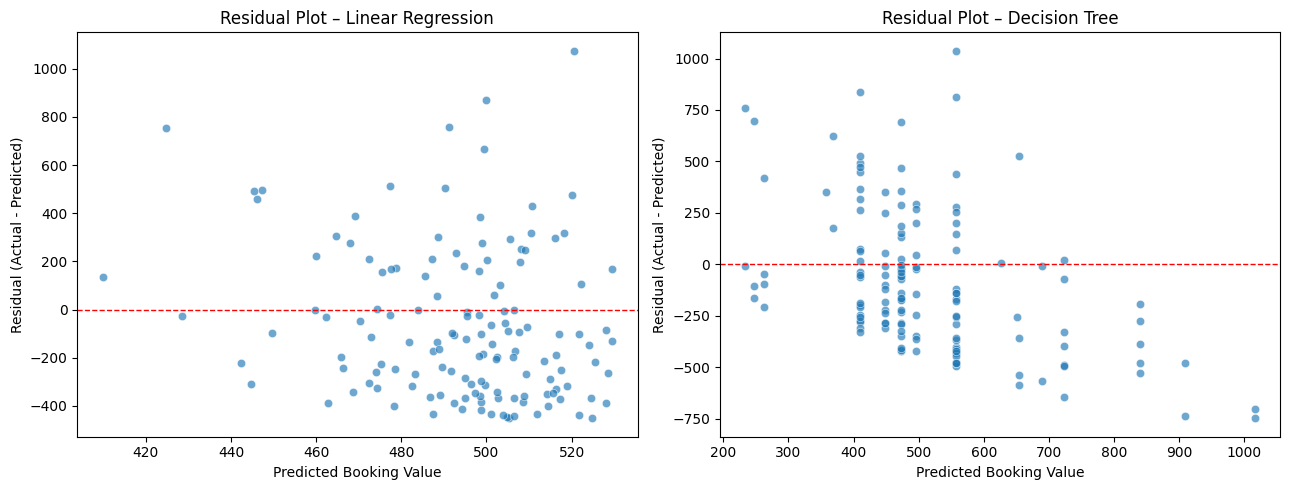

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - y_pred
    sns.scatterplot(x=y_pred, y=residuals, ax=ax, alpha=0.65)
    ax.axhline(0, color='red', linestyle='--', linewidth=1)
    ax.set_title(f'Residual Plot – {name}')
    ax.set_xlabel('Predicted Booking Value')
    ax.set_ylabel('Residual (Actual - Predicted)')
plt.tight_layout()
plt.show()


## 4. Actual vs. Predicted 

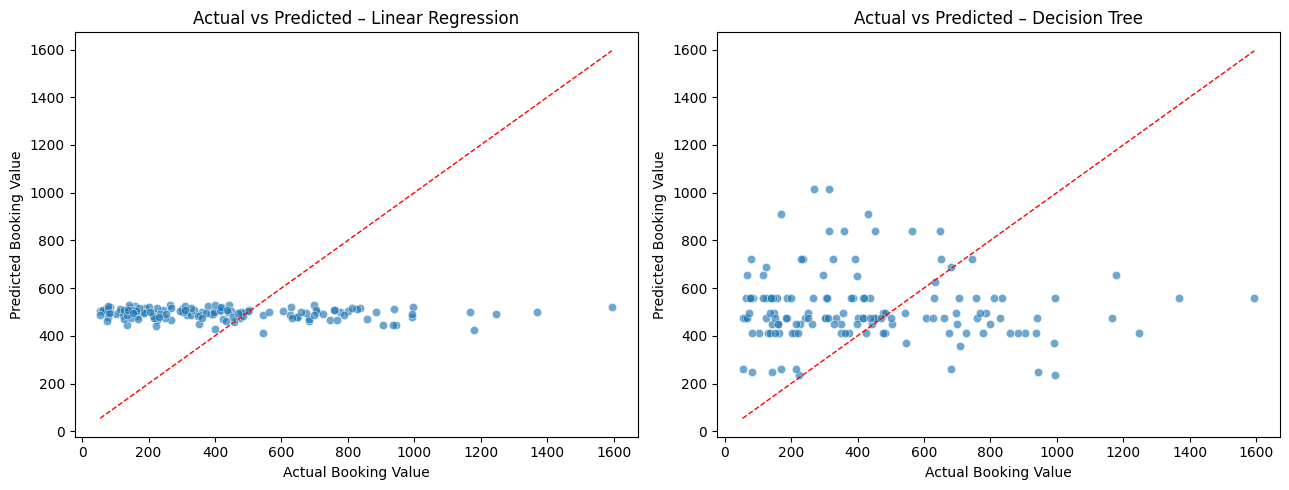

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    sns.scatterplot(x=y_test.to_numpy(), y=y_pred, ax=ax, alpha=0.65)
    low = min(y_test.min(), np.min(y_pred))
    high = max(y_test.max(), np.max(y_pred))
    ax.plot([low, high], [low, high], 'r--', linewidth=1)
    ax.set_title(f'Actual vs Predicted – {name}')
    ax.set_xlabel('Actual Booking Value')
    ax.set_ylabel('Predicted Booking Value')
plt.tight_layout()
plt.show()


## 5. Tự động chọn mô hình và nhận xét

**Tiêu chí:** RMSE và MSE càng thấp càng tốt; R² càng cao càng tốt. RMSE được dùng làm tiêu chí chính chọn mô hình ở đây, khi cả hai được đánh giá trên cùng test set.

**Lưu ý:** R² có thể âm; nếu R² ≤ 0, hiệu quả dự đoán trên tập test không tốt hơn dự đoán giá trị trung bình của train (theo tiêu chí bình phương sai số). Kết quả phụ thuộc dữ liệu, không khẳng định trước mô hình nào thắng.

In [70]:
winner = metrics_df.iloc[0]
print('MÔ HÌNH ĐƯỢC CHỌN:', winner['Mô hình'])
print(f"MSE = {winner['MSE']:.4f} | RMSE = {winner['RMSE']:.4f} | R² = {winner['R²']:.4f}")
if winner['R²'] <= 0:
    print('NHẬN XÉT: Khả năng dự đoán còn yếu trên test set; cần bổ sung feature có ý nghĩa.')
elif winner['R²'] < 0.5:
    print('NHẬN XÉT: Khả năng giải thích biến thiên Booking Value còn hạn chế.')
else:
    print('NHẬN XÉT: Mô hình có khả năng giải thích một phần đáng kể biến thiên mục tiêu.')
print('Đây là so sánh trên một lần chia dữ liệu, chưa phải bằng chứng tổng quát hóa chắc chắn.')


MÔ HÌNH ĐƯỢC CHỌN: Linear Regression
MSE = 101482.8958 | RMSE = 318.5638 | R² = -0.0703
NHẬN XÉT: Khả năng dự đoán còn yếu trên test set; cần bổ sung feature có ý nghĩa.
Đây là so sánh trên một lần chia dữ liệu, chưa phải bằng chứng tổng quát hóa chắc chắn.


## 6. Dự đoán thử cho chuyến xe mới

Thay `Ride Distance` và `Vehicle Type` bằng dữ liệu thực tế; loại xe nên thuộc các giá trị được quan sát trong tập train.

In [71]:
best_model = models[winner['Mô hình']]
print('Các loại xe trong tập train:', sorted(X_train['Vehicle Type'].dropna().unique()))
example = pd.DataFrame({
    'Ride Distance': [12.5],
    'Vehicle Type': [X_train['Vehicle Type'].mode().iloc[0]]
})
print('Thông tin chuyến xe:')
display(example)
print(f'Giá trị dự đoán (đơn vị của dataset): {best_model.predict(example)[0]:,.2f}')


Các loại xe trong tập train: ['Auto', 'Bike', 'Go Mini', 'Go Sedan', 'Premier Sedan', 'Uber XL', 'eBike']
Thông tin chuyến xe:


,Ride Distance,Vehicle Type
0,12.5,Auto


Giá trị dự đoán (đơn vị của dataset): 494.82


### Nhận xét kết quả

**1. So sánh hai mô hình**

- Linear Regression: MSE = 101482.8958, RMSE = 318.5638, R² = -0.0703.
- Decision Tree Regressor: MSE = 127796.6345, RMSE = 357.4866, R² = -0.3478.

Linear Regression có MSE và RMSE thấp hơn, đồng thời R² cao hơn Decision Tree. Điều này cho thấy Linear Regression có hiệu quả dự đoán tốt hơn trên tập kiểm thử.

**2. Phân tích Residual Plot**

- Linear Regression: Các điểm sai số phân tán khá rộng quanh đường 0, cho thấy mô hình vẫn có sai số dự đoán lớn.
- Decision Tree: Các điểm sai số tập trung thành nhiều dải dọc và có độ phân tán lớn, cho thấy mô hình chưa dự đoán chính xác giá trị Booking Value.

**3. Lựa chọn mô hình**

Nhóm lựa chọn **Linear Regression** vì có RMSE thấp hơn (318.5638 so với 357.4866) và R² cao hơn (-0.0703 so với -0.3478).

Tuy nhiên, cả hai mô hình đều có R² âm, cho thấy khả năng dự đoán trên tập kiểm thử chưa tốt. Nguyên nhân có thể do các biến đầu vào hiện tại chưa cung cấp đủ thông tin để dự đoán Booking Value.

**Kết luận:** Linear Regression là mô hình phù hợp hơn trong hai mô hình đã thử, nhưng cần bổ sung các đặc trưng có ý nghĩa và tiếp tục cải thiện mô hình trước khi ứng dụng thực tế.

# HỌC CÓ GIÁM SÁT: CLASSIFICATION

**Mục tiêu:** Dự đoán trạng thái đặt xe (`Booking Status`) bằng **Logistic Regression** và **Decision Tree Classifier**.

**Đầu ra:** Hai mô hình, Confusion Matrix, Classification Report, bảng so sánh Accuracy / Precision / Recall / F1-score và kết luận.

- Chạy các ô nạp và ghép dữ liệu ở đầu notebook trước để có `df_merge`.
- Phần này dùng dữ liệu Uber trong `df_merge` (hiện giới hạn 1.000 bản ghi), cùng nguồn với EDA. `df_concat` chưa được dùng để huấn luyện.
- Lấy dữ liệu **trước khi điền thiếu ở EDA**, không dùng `df_clean`. Việc điền thiếu, chuẩn hóa và mã hóa sẽ chỉ học trên train trong Pipeline.
- Nếu thiếu thư viện, chạy trong một ô riêng: `%pip install scikit-learn pandas numpy matplotlib`.

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

## 5.1. Chọn biến mục tiêu và biến đầu vào

**Thời điểm dự đoán:** Khi người dùng đặt xe. Giữ nguyên các lớp của `Booking Status`, không tự gộp thành hai lớp.

| Nhóm | Các biến | Cách sử dụng |
| --- | --- | --- |
| Đầu vào phân loại | `Vehicle Type`, `Pickup Location`, `Drop Location` | One-Hot Encoding |
| Đầu vào thời gian | Tháng, thứ trong tuần từ `Date`; giờ từ `Time` | Điền median và StandardScaler |
| Biến mục tiêu | `Booking Status` | LabelEncoder học trên train |
| Không đưa vào X | Mã đặt xe, mã khách hàng | Chỉ là mã định danh |
| Không đưa vào X | Cờ và lý do hủy/chưa hoàn thành, đánh giá, `Avg VTAT`, `Avg CTAT`, `Booking Value`, `Ride Distance`, `Payment Method` | Có thể chỉ được ghi nhận sau lúc đặt xe hoặc sau khi đã biết kết quả |
| Không đưa vào X | `Discount`, `Payment Status` | Dữ liệu giả lập ở phần merge |

Việc loại các cột trên giúp tránh để mô hình suy ra đáp án từ thông tin xuất hiện sau kết quả. Đây là lựa chọn thận trọng khi chưa có tài liệu xác nhận thời điểm ghi nhận từng cột.

In [73]:
# Sao chép dữ liệu trước bước điền thiếu của EDA
df_cls5 = df_merge.copy()
df_cls5 = df_cls5.dropna(subset=['Booking Status', 'Booking ID'])
df_cls5 = df_cls5.drop_duplicates(subset=['Booking ID']).reset_index(drop=True)
df_cls5['Booking Status'] = df_cls5['Booking Status'].astype(str).str.strip()
df_cls5 = df_cls5.loc[df_cls5['Booking Status'].ne('')].reset_index(drop=True)

cat_cols5 = ['Vehicle Type', 'Pickup Location', 'Drop Location']
num_cols5 = ['Month', 'DayOfWeek', 'Hour']

X5 = df_cls5[cat_cols5].copy()
for col5 in cat_cols5:
    X5[col5] = X5[col5].replace(r'^\s*$', np.nan, regex=True)

# Chỉ biến đổi theo từng dòng; chưa học thống kê từ toàn bộ dữ liệu
date5 = pd.to_datetime(df_cls5['Date'], format='%Y-%m-%d', errors='coerce')
time5 = pd.to_datetime(df_cls5['Time'], format='%H:%M:%S', errors='coerce')
X5['Month'] = date5.dt.month.astype(float)
X5['DayOfWeek'] = date5.dt.dayofweek.astype(float)  # 0: Thứ hai, 6: Chủ nhật
X5['Hour'] = time5.dt.hour.astype(float)
y_raw5 = df_cls5['Booking Status'].copy()

print('Số bản ghi dùng cho phân loại:', len(X5))
print('Các biến đầu vào:', X5.columns.tolist())
display(X5.head())

Số bản ghi dùng cho phân loại: 1000
Các biến đầu vào: ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Month', 'DayOfWeek', 'Hour']


,Vehicle Type,Pickup Location,Drop Location,Month,DayOfWeek,Hour
0,eBike,Palam Vihar,Jhilmil,3.0,5.0,12.0
1,Go Sedan,Shastri Nagar,Gurgaon Sector 56,11.0,4.0,18.0
2,Auto,Khandsa,Malviya Nagar,8.0,4.0,8.0
3,Premier Sedan,Central Secretariat,Inderlok,10.0,0.0,17.0
4,Bike,Ghitorni Village,Khan Market,9.0,0.0,22.0


,Số lượng,Tỷ lệ (%)
Booking Status,,
Completed,633,63.3
Cancelled by Driver,176,17.6
Cancelled by Customer,68,6.8
No Driver Found,64,6.4
Incomplete,59,5.9


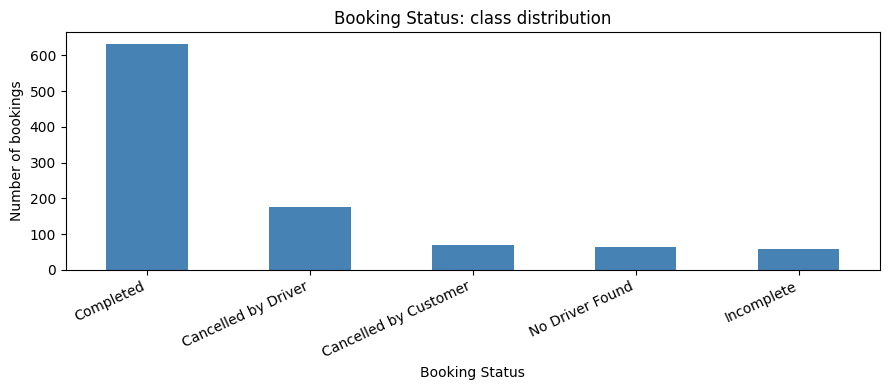

In [74]:
# Kiểm tra sự chênh lệch số lượng giữa các lớp
class_counts5 = y_raw5.value_counts()
class_distribution5 = pd.DataFrame({
    'Số lượng': class_counts5,
    'Tỷ lệ (%)': (class_counts5 / len(y_raw5) * 100).round(2)
})
display(class_distribution5)

ax5 = class_counts5.plot(kind='bar', figsize=(9, 4), color='steelblue')
ax5.set_title('Booking Status: class distribution')
ax5.set_xlabel('Booking Status')
ax5.set_ylabel('Number of bookings')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

## 5.2. Chia train/test và mã hóa nhãn

- Chia **80% train, 20% test**, cố định `random_state=42` để tái lập kết quả.
- Dùng `stratify` để tỷ lệ các trạng thái trong train/test gần với dữ liệu gốc.
- `LabelEncoder` chỉ học trên nhãn train; test dùng lại cách mã hóa đó.
- Test được giữ riêng. Cross-validation và mọi bước học tiền xử lý đều thực hiện trong tập train.

In [75]:
X_train5, X_test5, y_train_raw5, y_test_raw5 = train_test_split(
    X5, y_raw5, test_size=0.2, random_state=42, stratify=y_raw5
)

label_encoder5 = LabelEncoder()
y_train5 = label_encoder5.fit_transform(y_train_raw5)
y_test5 = label_encoder5.transform(y_test_raw5)
class_names5 = label_encoder5.classes_
labels5 = np.arange(len(class_names5))

print('Train:', X_train5.shape, '| Test:', X_test5.shape)
print('Số dòng trùng chỉ số giữa train/test:', len(X_train5.index.intersection(X_test5.index)))
display(pd.DataFrame({'Mã nhãn': labels5, 'Booking Status': class_names5}))

split_distribution5 = pd.DataFrame({
    'Train': y_train_raw5.value_counts(),
    'Test': y_test_raw5.value_counts(),
    'Train (%)': y_train_raw5.value_counts(normalize=True).mul(100),
    'Test (%)': y_test_raw5.value_counts(normalize=True).mul(100)
}).reindex(class_names5)
display(split_distribution5.round(2))

Train: (800, 6) | Test: (200, 6)
Số dòng trùng chỉ số giữa train/test: 0


,Mã nhãn,Booking Status
0,0,Cancelled by Customer
1,1,Cancelled by Driver
2,2,Completed
3,3,Incomplete
4,4,No Driver Found


,Train,Test,Train (%),Test (%)
Booking Status,,,,
Cancelled by Customer,55,13,6.88,6.5
Cancelled by Driver,141,35,17.62,17.5
Completed,506,127,63.25,63.5
Incomplete,47,12,5.88,6.0
No Driver Found,51,13,6.38,6.5


## 5.3. Tiền xử lý và xây dựng hai mô hình

- **Biến số:** Điền thiếu bằng median rồi chuẩn hóa bằng StandardScaler.
- **Biến phân loại:** Điền thiếu bằng mode rồi One-Hot Encoding. `handle_unknown='ignore'` giúp xử lý địa điểm mới trong test.
- Hai mô hình dùng hai bản sao Pipeline độc lập, cùng tập train/test và cùng biến đầu vào.
- Dùng `class_weight='balanced'` để tăng trọng số cho lớp ít mẫu. Cách này không bảo đảm Accuracy tăng.
- Cây quyết định giới hạn `max_depth=5`, `min_samples_leaf=10` để hạn chế học quá sát dữ liệu train. Các tham số được cố định trước khi đánh giá test.

**So sánh trên train:** Stratified 5-fold cross-validation với F1-macro. Chọn mô hình theo điểm CV; sau đó báo cáo kết quả test của cả hai. Không chỉnh tham số theo test.

Pipeline được fit lại trong từng fold nên median, mode, StandardScaler và One-Hot Encoding không học từ fold kiểm định.

In [76]:
numeric_pipeline5 = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline5 = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor5 = ColumnTransformer([
    ('numeric', numeric_pipeline5, num_cols5),
    ('categorical', categorical_pipeline5, cat_cols5)
])

models5 = {
    'Logistic Regression': Pipeline([
        ('preprocess', clone(preprocessor5)),
        ('model', LogisticRegression(
            max_iter=2000, class_weight='balanced', random_state=42
        ))
    ]),
    'Decision Tree': Pipeline([
        ('preprocess', clone(preprocessor5)),
        ('model', DecisionTreeClassifier(
            max_depth=5, min_samples_leaf=10,
            class_weight='balanced', random_state=42
        ))
    ])
}

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores5 = {}
for name5, model5 in models5.items():
    cv_scores5[name5] = cross_val_score(
        model5, X_train5, y_train5, cv=cv5, scoring='f1_macro', n_jobs=1
    )
    model5.fit(X_train5, y_train5)
    print(f'{name5}: CV F1-macro = {cv_scores5[name5].mean():.4f}'
          f' ± {cv_scores5[name5].std():.4f}')

Logistic Regression: CV F1-macro = 0.1559 ± 0.0170
Decision Tree: CV F1-macro = 0.1247 ± 0.0250


## 5.4. Đánh giá trên tập test

- **Confusion Matrix:** Hàng là nhãn thật, cột là nhãn dự đoán. Đường chéo là số dự đoán đúng.
- **Accuracy:** Tỷ lệ dự đoán đúng trên toàn bộ test.
- **Precision:** Trong các mẫu được dự đoán thuộc một lớp, bao nhiêu mẫu thực sự thuộc lớp đó.
- **Recall:** Trong các mẫu thực sự thuộc một lớp, mô hình tìm đúng được bao nhiêu mẫu.
- **F1-score:** Kết hợp Precision và Recall. Bảng so sánh ưu tiên **macro** vì mỗi lớp có trọng số bằng nhau; F1-weighted bổ sung trọng số theo số mẫu.
- Classification Report hiển thị từng lớp và `support` (số mẫu thật của lớp trong test). `zero_division=0` trả 0 khi một chỉ số không tính được do không có mẫu dự đoán của lớp đó.


LOGISTIC REGRESSION
                       precision    recall  f1-score   support

Cancelled by Customer     0.0476    0.0769    0.0588        13
  Cancelled by Driver     0.1373    0.2000    0.1628        35
            Completed     0.6049    0.3858    0.4712       127
           Incomplete     0.0000    0.0000    0.0000        12
      No Driver Found     0.0909    0.1538    0.1143        13

             accuracy                         0.2950       200
            macro avg     0.1761    0.1633    0.1614       200
         weighted avg     0.4172    0.2950    0.3389       200


DECISION TREE
                       precision    recall  f1-score   support

Cancelled by Customer     0.1364    0.2308    0.1714        13
  Cancelled by Driver     0.1905    0.2286    0.2078        35
            Completed     0.6667    0.0157    0.0308       127
           Incomplete     0.0345    0.1667    0.0571        12
      No Driver Found     0.0400    0.2308    0.0682        13

             a

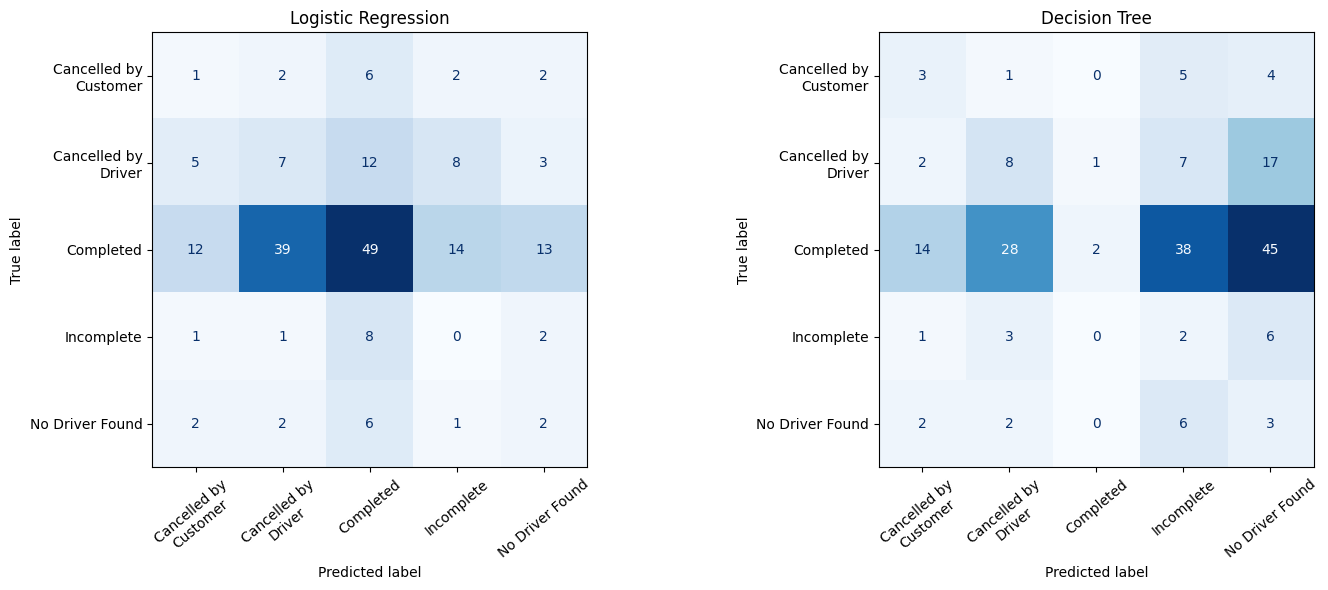

,Model,CV F1-macro,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
0,Logistic Regression,0.1559,0.295,0.1761,0.1633,0.1614,0.3389
1,Decision Tree,0.1247,0.090,0.2136,0.1745,0.1071,0.0749


In [77]:
predictions5 = {}
reports5 = {}
confusion_matrices5 = {}
result_rows5 = []

fig5, axes5 = plt.subplots(1, 2, figsize=(15, 6))
for ax5, (name5, model5) in zip(axes5, models5.items()):
    y_pred5 = model5.predict(X_test5)
    predictions5[name5] = y_pred5
    cm5 = confusion_matrix(y_test5, y_pred5, labels=labels5)
    confusion_matrices5[name5] = cm5

    print('\n' + name5.upper())
    print(classification_report(
        y_test5, y_pred5, labels=labels5, target_names=class_names5,
        digits=4, zero_division=0
    ))
    reports5[name5] = pd.DataFrame(classification_report(
        y_test5, y_pred5, labels=labels5, target_names=class_names5,
        output_dict=True, zero_division=0
    )).T

    result_rows5.append({
        'Model': name5,
        'CV F1-macro': cv_scores5[name5].mean(),
        'Accuracy': accuracy_score(y_test5, y_pred5),
        'Precision (macro)': precision_score(
            y_test5, y_pred5, labels=labels5, average='macro', zero_division=0),
        'Recall (macro)': recall_score(
            y_test5, y_pred5, labels=labels5, average='macro', zero_division=0),
        'F1 (macro)': f1_score(
            y_test5, y_pred5, labels=labels5, average='macro', zero_division=0),
        'F1 (weighted)': f1_score(
            y_test5, y_pred5, labels=labels5, average='weighted', zero_division=0)
    })

    ConfusionMatrixDisplay(
        confusion_matrix=cm5,
        display_labels=[fill(label5, width=17) for label5 in class_names5]
    ).plot(ax=ax5, cmap='Blues', colorbar=False, xticks_rotation=40)
    ax5.set_title(name5)
    ax5.set_xlabel('Predicted label')
    ax5.set_ylabel('True label')

plt.tight_layout()
plt.show()

results_classification5 = pd.DataFrame(result_rows5).sort_values(
    'CV F1-macro', ascending=False
).reset_index(drop=True)
display(results_classification5.round(4))

Lớp phổ biến nhất trong train: Completed
Mốc tham chiếu trên test: Accuracy = 0.6350; F1-macro = 0.1554
Mốc này giúp kiểm tra Accuracy có chỉ phản ánh lớp đông nhất hay không.


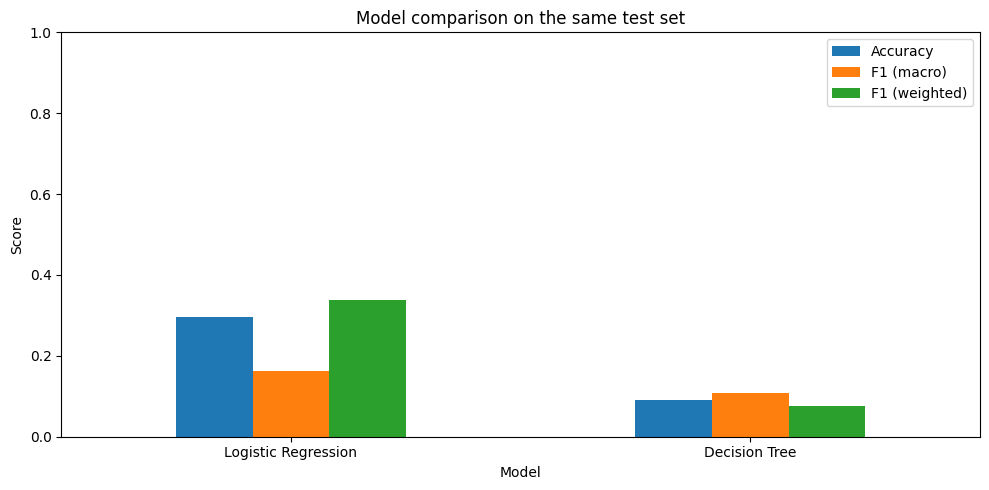

In [78]:
# Mốc tham chiếu: luôn đoán lớp phổ biến nhất trong TRAIN
majority_class5 = np.bincount(y_train5).argmax()
baseline_pred5 = np.full_like(y_test5, majority_class5)
baseline_accuracy5 = accuracy_score(y_test5, baseline_pred5)
baseline_f1_macro5 = f1_score(
    y_test5, baseline_pred5, labels=labels5, average='macro', zero_division=0
)
print('Lớp phổ biến nhất trong train:', class_names5[majority_class5])
print(f'Mốc tham chiếu trên test: Accuracy = {baseline_accuracy5:.4f}; '
      f'F1-macro = {baseline_f1_macro5:.4f}')
print('Mốc này giúp kiểm tra Accuracy có chỉ phản ánh lớp đông nhất hay không.')

ax5 = results_classification5.set_index('Model')[
    ['Accuracy', 'F1 (macro)', 'F1 (weighted)']
].plot(kind='bar', figsize=(10, 5), rot=0)
ax5.set_title('Model comparison on the same test set')
ax5.set_xlabel('Model')
ax5.set_ylabel('Score')
ax5.set_ylim(0, 1)
ax5.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 5.5. Kết luận

Ô dưới tự lấy số liệu sau khi chạy, tránh ghi nhận xét bằng các số chưa được kiểm chứng. Mô hình đứng đầu được chọn theo **F1-macro trung bình trong cross-validation của train**, không chọn theo kết quả test.

In [79]:
best_row5 = results_classification5.iloc[0]
best_name5 = best_row5['Model']
best_model5 = models5[best_name5]

print('KẾT LUẬN PHẦN 5')
print(f'1. Dùng {len(X5)} bản ghi, {len(class_names5)} lớp; '
      f'train {len(X_train5)} và test {len(X_test5)} bản ghi.')
print(f'2. Lớp nhiều nhất là {class_counts5.index[0]}, '
      f'chiếm {class_counts5.iloc[0] / len(y_raw5):.2%} trong mẫu hiện tại.')
print(f'3. {best_name5} có F1-macro CV cao nhất trong hai mô hình: '
      f'{best_row5["CV F1-macro"]:.4f}.')
print(f'   Trên test: Accuracy = {best_row5["Accuracy"]:.4f}; '
      f'Precision-macro = {best_row5["Precision (macro)"]:.4f}; '
      f'Recall-macro = {best_row5["Recall (macro)"]:.4f}; '
      f'F1-macro = {best_row5["F1 (macro)"]:.4f}.')

if best_row5['Accuracy'] <= baseline_accuracy5:
    print('4. Accuracy chưa vượt mốc luôn đoán lớp phổ biến nhất. '
          'Cần xem thêm F1-macro và báo cáo từng lớp; chưa thể coi mô hình là tốt.')
else:
    print('4. Accuracy vượt mốc luôn đoán lớp phổ biến nhất trong lần chia này. '
          'Vẫn cần xem F1-macro và các lớp ít mẫu trước khi kết luận.')

if best_row5['F1 (macro)'] <= baseline_f1_macro5:
    print('   F1-macro cũng chưa vượt mốc tham chiếu, nên chưa thấy lợi ích '
          'phân loại rõ ràng trong lần đánh giá này.')

per_class5 = reports5[best_name5].loc[class_names5]
weakest_class5 = per_class5['f1-score'].idxmin()
print(f'5. Lớp có F1 thấp nhất của mô hình được chọn: {weakest_class5} '
      f'(F1 = {per_class5.loc[weakest_class5, "f1-score"]:.4f}).')
print('6. Đây là kết quả thử nghiệm trên mẫu nhỏ. Cần tăng dữ liệu đại diện, '
      'bổ sung thông tin có sẵn lúc đặt xe và đánh giá trên dữ liệu mới.')

KẾT LUẬN PHẦN 5
1. Dùng 1000 bản ghi, 5 lớp; train 800 và test 200 bản ghi.
2. Lớp nhiều nhất là Completed, chiếm 63.30% trong mẫu hiện tại.
3. Logistic Regression có F1-macro CV cao nhất trong hai mô hình: 0.1559.
   Trên test: Accuracy = 0.2950; Precision-macro = 0.1761; Recall-macro = 0.1633; F1-macro = 0.1614.
4. Accuracy chưa vượt mốc luôn đoán lớp phổ biến nhất. Cần xem thêm F1-macro và báo cáo từng lớp; chưa thể coi mô hình là tốt.
5. Lớp có F1 thấp nhất của mô hình được chọn: Incomplete (F1 = 0.0000).
6. Đây là kết quả thử nghiệm trên mẫu nhỏ. Cần tăng dữ liệu đại diện, bổ sung thông tin có sẵn lúc đặt xe và đánh giá trên dữ liệu mới.


### Hạn chế và hướng cải thiện

- Notebook hiện lấy 1.000 dòng đầu của bộ Uber, chưa phản ánh toàn bộ dữ liệu và chưa dùng dữ liệu Ola trong mô hình phân loại.
- Các biến đầu vào được giới hạn ở thông tin có tại lúc đặt xe. Nếu điểm số thấp, cần báo cáo đúng; không thêm lý do hủy hoặc dấu hiệu kết thúc chuyến chỉ để tăng điểm.
- `class_weight='balanced'` hỗ trợ học lớp ít mẫu, nhưng vẫn có thể làm giảm Accuracy. Đọc Classification Report để biết mô hình đang bỏ sót lớp nào.
- Kết quả chỉ dựa trên một lần chia train/test và CV trong train. Nếu dự đoán chuyến xe tương lai, cần đánh giá thêm bằng cách chia theo thời gian.
- Dữ liệu test không tham gia bước học median, mode, chuẩn hóa, mã hóa đặc trưng hoặc chọn mô hình. Tuy nhiên, EDA trước đó đã xem toàn bộ mẫu; đây vẫn là bài thực hành, cần một tập dữ liệu mới để kiểm chứng độc lập.
- Có thể cải thiện bằng dữ liệu lớn hơn, biến nhu cầu/cung tài xế có sẵn lúc đặt xe và tìm tham số bằng cross-validation trong train.

**Các biến có thể dùng khi tích hợp:** `models5`, `label_encoder5`, `X_train5`, `X_test5`, `y_train5`, `y_test5`, `predictions5`, `reports5`, `confusion_matrices5`, `results_classification5`, `best_model5`.

**Tài liệu tham khảo:** [Pipeline và tránh rò rỉ dữ liệu](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage), [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).

# Dimensionality Reduction (PCA)
Mục tiêu:
- Chọn đặc trưng phù hợp và loại mã định danh.
- Mã hóa các biến phân loại được chọn.
- Chuẩn hóa bằng StandardScaler.
- Chạy PCA, tính phương sai giải thích tích lũy và chọn số thành phần giữ khoảng 90% phương sai.
- Vẽ biểu đồ phương sai tích lũy và scatter plot của hai thành phần chính đầu tiên.

## Import thư viện

In [80]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## Bước 1:Kiểm tra dữ liệu đầu vào

In [81]:
print("Kích thước dữ liệu:", df_clean.shape)
print("Danh sách cột:")
print(df_clean.columns.tolist())

display(df_clean.head())

Kích thước dữ liệu: (1000, 23)
Danh sách cột:
['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method', 'Discount', 'Payment Status']


,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method,Discount,Payment Status
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,8.1,28.2,...,More than permitted people in there,1.0,Vehicle Breakdown,400.0,24.50,4.3,4.5,UPI,4462,Failed
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,More than permitted people in there,1.0,Vehicle Breakdown,237.0,5.73,4.3,4.5,UPI,38697,Failed
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,More than permitted people in there,1.0,Vehicle Breakdown,627.0,13.58,4.9,4.9,Debit Card,32728,Pending
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,More than permitted people in there,1.0,Vehicle Breakdown,416.0,34.02,4.6,5.0,UPI,21943,Failed
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,More than permitted people in there,1.0,Vehicle Breakdown,737.0,48.21,4.1,4.3,UPI,21650,Paid


## Bước 2: Chọn các đặc trưng phù hợp

In [82]:
# Các đặc trưng dạng số
numeric_features = [
    "Avg VTAT",
    "Avg CTAT",
    "Booking Value",
    "Ride Distance",
    "Driver Ratings",
    "Customer Rating",
    "Discount"
]

# Các đặc trưng phân loại
categorical_features = [
    "Vehicle Type",
    "Payment Method"
]

# Chỉ giữ các cột thực sự có trong dữ liệu
numeric_features = [
    col for col in numeric_features
    if col in df_clean.columns
    and pd.api.types.is_numeric_dtype(df_clean[col])
    and df_clean[col].nunique() > 1
]

categorical_features = [
    col for col in categorical_features
    if col in df_clean.columns
    and df_clean[col].nunique() > 1
]

print("Đặc trưng số:", numeric_features)
print("Đặc trưng phân loại:", categorical_features)

Đặc trưng số: ['Avg VTAT', 'Avg CTAT', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Discount']
Đặc trưng phân loại: ['Vehicle Type', 'Payment Method']


## Giải thích:
- Chọn các biến có ý nghĩa đối với chuyến xe.
- Loại Booking ID và Customer ID vì đây là mã định danh, không phải đặc trưng đo lường.
- Loại các cột không có biến thiên, chẳng hạn cột mà tất cả giá trị đều giống nhau.
- Không đưa Booking Status vào bộ đặc trưng PCA này, vì đây có thể là biến mục tiêu cho bài toán Classification.

## Bước 3: Tạo ma trận dữ liệu và mã hóa biến phân loại

In [83]:
# Lấy các cột đã chọn
X = df_clean[numeric_features + categorical_features].copy()

# Mã hóa biến phân loại thành các cột 0 và 1
X = pd.get_dummies(
    X,
    columns=categorical_features,
    dtype=int
)

# Xử lý giá trị vô cực nếu có
X = X.replace([np.inf, -np.inf], np.nan)

# Điền giá trị thiếu còn lại bằng trung vị
X = X.fillna(X.median())

# Loại các cột không có biến thiên
X = X.loc[:, X.nunique() > 1]

print("Kích thước ma trận đặc trưng:", X.shape)
display(X.head())

Kích thước ma trận đặc trưng: (1000, 19)


,Avg VTAT,Avg CTAT,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Discount,Vehicle Type_Auto,Vehicle Type_Bike,Vehicle Type_Go Mini,Vehicle Type_Go Sedan,Vehicle Type_Premier Sedan,Vehicle Type_Uber XL,Vehicle Type_eBike,Payment Method_Cash,Payment Method_Credit Card,Payment Method_Debit Card,Payment Method_UPI,Payment Method_Uber Wallet
0,8.1,28.2,400.0,24.50,4.3,4.5,4462,0,0,0,0,0,0,1,0,0,0,1,0
1,4.9,14.0,237.0,5.73,4.3,4.5,38697,0,0,0,1,0,0,0,0,0,0,1,0
2,13.4,25.8,627.0,13.58,4.9,4.9,32728,1,0,0,0,0,0,0,0,0,1,0,0
3,13.1,28.5,416.0,34.02,4.6,5.0,21943,0,0,0,0,1,0,0,0,0,0,1,0
4,5.3,19.6,737.0,48.21,4.1,4.3,21650,0,1,0,0,0,0,0,0,0,0,1,0


## Giải thích:

PCA yêu cầu dữ liệu dạng số. Vì vậy, Vehicle Type và Payment Method cần được mã hóa bằng pd.get_dummies().

## Bước 5: Chuẩn hóa dữ liệu bằng StandardScaler

In [84]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Kích thước dữ liệu sau chuẩn hóa:", X_scaled.shape)
print("Trung bình của các cột (một vài cột đầu):")
print(X_scaled.mean(axis=0)[:5].round(4))

Kích thước dữ liệu sau chuẩn hóa: (1000, 19)
Trung bình của các cột (một vài cột đầu):
[ 0.  0. -0.  0.  0.]


## Giải thích:

Các biến có đơn vị và độ lớn khác nhau. Ví dụ, Booking Value có thể lớn hơn nhiều so với Driver Ratings.

StandardScaler đưa các biến về cùng thang đo, thường có trung bình gần 0 và độ lệch chuẩn gần 1. Điều này giúp PCA tránh bị chi phối quá nhiều bởi các biến có giá trị lớn.

## Bước 6: Chạy PCA và tính phương sai tích lũy

In [85]:
pca_full = PCA()

X_pca_full = pca_full.fit_transform(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_table = pd.DataFrame({
    "Thành phần chính": [
        f"PC{i + 1}" for i in range(len(explained_variance))
    ],
    "Tỷ lệ phương sai giải thích": explained_variance,
    "Tỷ lệ phương sai tích lũy": cumulative_variance
})

# Chuyển tỷ lệ sang phần trăm
variance_table["Tỷ lệ phương sai giải thích"] = (
    variance_table["Tỷ lệ phương sai giải thích"].map("{:.2%}".format)
)

variance_table["Tỷ lệ phương sai tích lũy"] = (
    variance_table["Tỷ lệ phương sai tích lũy"].map("{:.2%}".format)
)

display(variance_table)

,Thành phần chính,Tỷ lệ phương sai giải thích,Tỷ lệ phương sai tích lũy
0,PC1,9.69%,9.69%
1,PC2,7.38%,17.07%
2,PC3,6.85%,23.93%
3,PC4,6.71%,30.63%
4,PC5,6.42%,37.05%
5,PC6,6.34%,43.39%
6,PC7,6.23%,49.62%
7,PC8,5.91%,55.53%
8,PC9,5.71%,61.24%
9,PC10,5.52%,66.76%


## Bước 7: Vẽ biểu đồ phương sai tích lũy

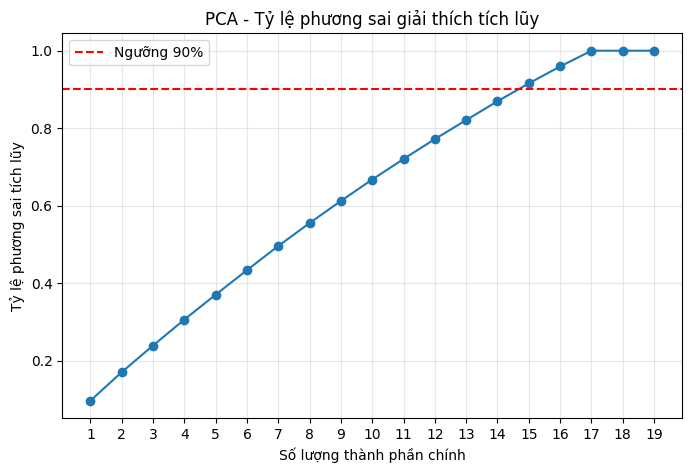

In [86]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.90,
    color="red",
    linestyle="--",
    label="Ngưỡng 90%"
)

plt.xlabel("Số lượng thành phần chính")
plt.ylabel("Tỷ lệ phương sai tích lũy")
plt.title("PCA - Tỷ lệ phương sai giải thích tích lũy")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Bước 8: Chọn số thành phần chính

In [87]:
# Chọn số thành phần chính nhỏ nhất giữ ít nhất 90% phương sai
nguong_phuong_sai = 0.90

so_thanh_phan = np.argmax(
    cumulative_variance >= nguong_phuong_sai
) + 1

print("Số lượng thành phần chính được chọn:", so_thanh_phan)
print(
    "Tỷ lệ phương sai tích lũy:",
    f"{cumulative_variance[so_thanh_phan - 1]:.2%}"
)

Số lượng thành phần chính được chọn: 15
Tỷ lệ phương sai tích lũy: 91.57%


Giải thích: Code tự động tìm số thành phần nhỏ nhất đạt ngưỡng 90%. Bạn không cần tự đoán số PC.

## Bước 9: Tạo ma trận PCA cuối cùng

In [88]:
pca = PCA(n_components=so_thanh_phan)

X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(
    X_pca,
    columns=[
        f"PC{i + 1}" for i in range(so_thanh_phan)
    ],
    index=df_clean.index
)

print("Kích thước trước PCA:", X.shape)
print("Kích thước sau PCA:", df_pca.shape)

display(df_pca.head())

Kích thước trước PCA: (1000, 19)
Kích thước sau PCA: (1000, 15)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15
0,-1.462504,-0.620161,-0.469248,-0.051813,0.092988,0.899183,-0.578708,-2.335606,1.242089,1.976369,-0.310813,1.789444,-0.117776,-0.365857,1.031895
1,-1.434389,0.075346,2.509854,1.159022,0.905536,-0.350286,-0.914093,0.894501,0.426515,0.204970,0.056112,-0.723286,-0.163325,-1.407712,-0.354828
2,0.996758,2.988239,1.738034,-0.411480,-0.200860,-0.991366,1.669825,0.433839,1.327279,-0.701899,0.600922,2.671383,0.595093,0.954438,-0.763678
3,-1.193859,-0.774371,-0.038690,-0.833914,-1.192740,1.624591,0.203261,0.870333,-0.218958,-0.841982,1.315882,1.201642,0.156826,1.095546,-0.876620
4,0.096287,-0.445188,-0.444672,-0.381627,1.484048,1.276392,1.570226,-1.174271,0.303982,-0.671762,-0.788811,-1.795327,-0.736204,-0.072781,-0.402044


### Giải thích:

df_pca là ma trận dữ liệu sau giảm chiều. Ví dụ, nếu ban đầu có 10 đặc trưng được mã hóa nhưng PCA chọn 5 thành phần, số cột sẽ giảm từ 10 xuống 5.

## Bước 10: Scatter plot hai thành phần chính đầu tiên

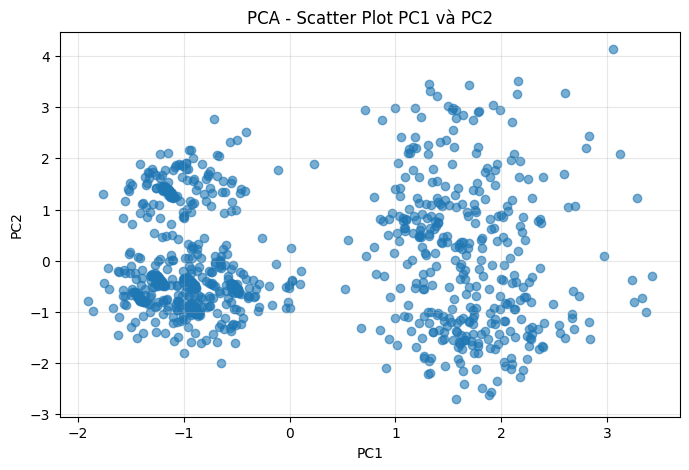

In [89]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca_full[:, 0],
    X_pca_full[:, 1],
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Scatter Plot PC1 và PC2")
plt.grid(True, alpha=0.3)
plt.show()

### Giải thích: 
Biểu đồ biểu diễn mỗi dòng dữ liệu trên hai trục PC1 và PC2. Nó giúp quan sát cấu trúc phân bố và những nhóm điểm có thể tồn tại. Tuy nhiên, chỉ nhìn biểu đồ này chưa đủ để khẳng định dữ liệu có các cụm rõ ràng.

## Bước 11: Nhận xét kết quả tự động

In [90]:
print("KẾT LUẬN PCA")
print("- Số đặc trưng ban đầu:", X.shape[1])
print("- Số thành phần chính được giữ lại:", so_thanh_phan)
print(
    "- Phương sai được giữ lại:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

if so_thanh_phan < X.shape[1]:
    print("- PCA đã giảm số chiều dữ liệu.")
else:
    print("- PCA chưa giảm số chiều với ngưỡng đã chọn.")

KẾT LUẬN PCA
- Số đặc trưng ban đầu: 19
- Số thành phần chính được giữ lại: 15
- Phương sai được giữ lại: 91.57%
- PCA đã giảm số chiều dữ liệu.


**K-MEANS TRÊN DỮ LIỆU GỐC**

Chọn 5 đặc trưng: Ride Distance, Booking Value, Avg VTAT, Avg CTAT và Vehicle Type.

Các cột Booking Status, Booking ID, Customer ID không dùng trực tiếp để phân cụm.

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score

# Chọn đặc trưng
numeric_features = [
    "Ride Distance",
    "Booking Value",
    "Avg VTAT",
    "Avg CTAT"
]

categorical_features = [
    "Vehicle Type"
]

features = numeric_features + categorical_features

# Tạo DataFrame riêng
df_kmeans = df_clean[features].copy()

display(df_kmeans.head())
print(df_kmeans.isnull().sum())

,Ride Distance,Booking Value,Avg VTAT,Avg CTAT,Vehicle Type
0,24.50,400.0,8.1,28.2,eBike
1,5.73,237.0,4.9,14.0,Go Sedan
2,13.58,627.0,13.4,25.8,Auto
3,34.02,416.0,13.1,28.5,Premier Sedan
4,48.21,737.0,5.3,19.6,Bike


Ride Distance    0
Booking Value    0
Avg VTAT         0
Avg CTAT         0
Vehicle Type     0
dtype: int64


chuẩn hóa dữ liệu

In [92]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Các đặc trưng số
numeric_features = [
    "Ride Distance",
    "Booking Value",
    "Avg VTAT",
    "Avg CTAT"
]

# Đặc trưng phân loại
categorical_features = ["Vehicle Type"]

# Chuẩn hóa số và mã hóa loại xe
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    sparse_threshold=0
)

# Thực hiện chuyển đổi dữ liệu
X_scaled = preprocessor.fit_transform(df_kmeans)

print("Kích thước dữ liệu:", X_scaled.shape)
print("5 dòng đầu sau khi chuẩn hóa:")
print(X_scaled[:5])

Kích thước dữ liệu: (1000, 11)
5 dòng đầu sau khi chuẩn hóa:
[[-5.62154321e-02 -1.86157872e-01 -5.90638641e-02 -3.89580483e-02
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  1.00000000e+00]
 [-1.64242679e+00 -7.11572283e-01 -9.70807063e-01 -1.96180923e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [-9.79040582e-01  5.45554222e-01  1.45101081e+00 -3.63946981e-01
   1.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 7.48298801e-01 -1.34583451e-01  1.36553488e+00  1.66556828e-03
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   1.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 1.94746445e+00  9.00128365e-01 -8.56839164e-01 -1.20350172e+00
   0.00000000e+00  1.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00]]


hiển thị chuẩn hóa đẹp hơn

In [93]:
# Lấy tên 11 đặc trưng sau xử lý
column_names = preprocessor.get_feature_names_out()

# Tạo DataFrame
df_scaled = pd.DataFrame(
    X_scaled,
    columns=column_names,
    index=df_kmeans.index
)

# Hiển thị 5 dòng đầu, làm tròn 3 chữ số
display(df_scaled.head().round(3))

,num__Ride Distance,num__Booking Value,num__Avg VTAT,num__Avg CTAT,cat__Vehicle Type_Auto,cat__Vehicle Type_Bike,cat__Vehicle Type_Go Mini,cat__Vehicle Type_Go Sedan,cat__Vehicle Type_Premier Sedan,cat__Vehicle Type_Uber XL,cat__Vehicle Type_eBike
0,-0.056,-0.186,-0.059,-0.039,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-1.642,-0.712,-0.971,-1.962,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,-0.979,0.546,1.451,-0.364,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.748,-0.135,1.366,0.002,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.947,0.900,-0.857,-1.204,0.0,1.0,0.0,0.0,0.0,0.0,0.0


chạy elbow tìm K

c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\subprocess.py", line 489, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\subprocess.py", line 854, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\subproces

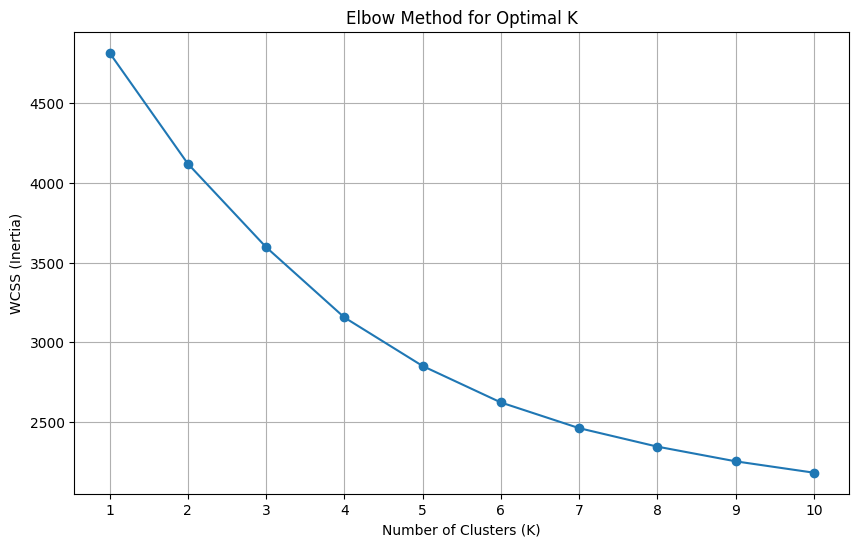

In [94]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Danh sách lưu WCSS
wcss = []

# Thử K từ 1 đến 10
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Vẽ biểu đồ Elbow
plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    wcss,
    marker="o",
    linestyle="-"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

**KẾT LUẬN:** Dựa vào Elbow Method, lựa chọn K = 5 vì sau giá trị này, WCSS có xu hướng giảm chậm hơn. Kết quả gợi ý phân chia dữ liệu thành 5 cụm, đồng thời cần đánh giá thêm bằng Silhouette Score để xác nhận mức độ phù hợp.

huấn luyện k-means với k=5

In [95]:
from sklearn.cluster import KMeans

# Chọn K = 5
optimal_k = 5

# Khởi tạo K-Means
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Huấn luyện và phân cụm
cluster_labels = kmeans.fit_predict(X_scaled)

# Tạo DataFrame mới từ df_clean
df_clustered = df_clean.copy()

# Thêm cột Cluster
df_clustered["Cluster"] = cluster_labels

# Hiển thị kết quả
display(df_clustered[
    ["Ride Distance", "Booking Value",
     "Avg VTAT", "Avg CTAT",
     "Vehicle Type", "Cluster"]
].head(10))

,Ride Distance,Booking Value,Avg VTAT,Avg CTAT,Vehicle Type,Cluster
0,24.50,400.0,8.1,28.2,eBike,0
1,5.73,237.0,4.9,14.0,Go Sedan,0
2,13.58,627.0,13.4,25.8,Auto,1
3,34.02,416.0,13.1,28.5,Premier Sedan,1
4,48.21,737.0,5.3,19.6,Bike,2
5,4.85,316.0,5.1,18.1,Auto,0
6,41.24,640.0,7.1,20.4,Go Mini,2
7,6.56,136.0,12.1,16.5,Auto,1
8,24.50,400.0,8.1,28.2,Go Sedan,0
9,10.36,135.0,6.1,26.0,Auto,0


thống kê số lượng chuyến xe trong từng cụm

Số lượng chuyến xe trong từng cụm:


Cluster
0    392
1    242
2    130
3     60
4    176
Name: count, dtype: int64

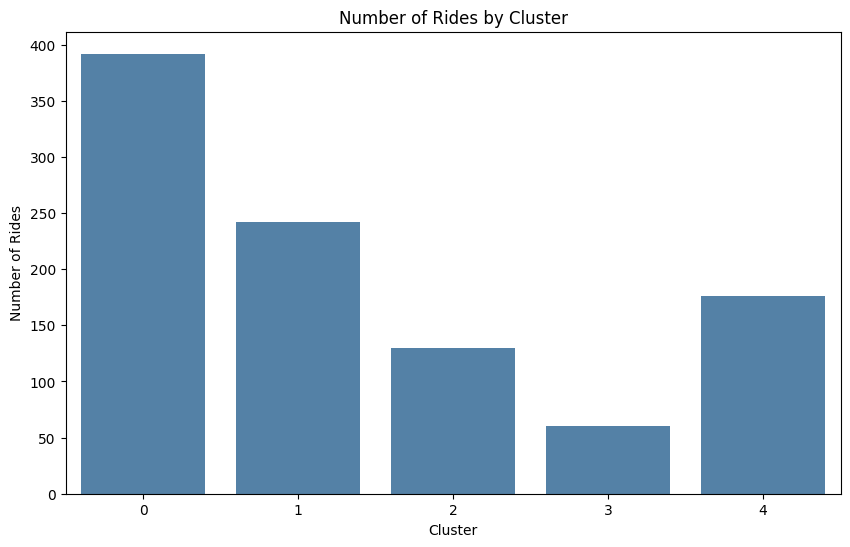

In [96]:
# Đếm số lượng chuyến trong từng cụm
cluster_counts = df_clustered["Cluster"].value_counts().sort_index()

print("Số lượng chuyến xe trong từng cụm:")
display(cluster_counts)

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_clustered,
    x="Cluster",
    color="steelblue"
)

plt.title("Number of Rides by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Rides")
plt.show()

KẾT LUẬN – Number of Rides by Cluster
Biểu đồ cho thấy thuật toán K-Means (K = 5) đã phân chia 1.000 chuyến xe thành 5 cụm với số lượng không đồng đều:
- Cụm 0: 392 chuyến (39,2%), chiếm tỷ lệ cao nhất.
- Cụm 1: 242 chuyến (24,2%).
- Cụm 2: 130 chuyến (13%).
- Cụm 3: 60 chuyến (6%), thấp nhất.
- Cụm 4: 176 chuyến (17,6%).
So What? Phần lớn chuyến xe tập trung ở cụm 0 và cụm 1, chiếm tổng cộng 63,4%. Điều này cho thấy dữ liệu phân bố không đồng đều giữa các cụm, nhưng chưa đủ cơ sở để đánh giá chất lượng phân cụm.

Ý nghĩa đối với mô hình AI: Cần phân tích thêm các đặc trưng như Ride Distance, Booking Value, Avg VTAT, Avg CTAT và Vehicle Type để xác định đặc điểm từng cụm. Đồng thời, sử dụng Silhouette Score để đánh giá mức độ phân tách của mô hình K-Means.

mô tả đặc điểm từng cụm

In [97]:
cluster_summary = df_clustered.groupby("Cluster").agg(
    Number_of_Rides=("Booking ID", "count"),
    Avg_Ride_Distance=("Ride Distance", "mean"),
    Avg_Booking_Value=("Booking Value", "mean"),
    Avg_VTAT=("Avg VTAT", "mean"),
    Avg_CTAT=("Avg CTAT", "mean")
)

display(cluster_summary.round(2))

,Number_of_Rides,Avg_Ride_Distance,Avg_Booking_Value,Avg_VTAT,Avg_CTAT
Cluster,,,,,
0,392,19.52,392.02,6.42,26.25
1,242,20.30,409.86,12.51,27.95
2,130,41.41,372.75,7.76,22.58
3,60,26.15,1337.83,7.74,25.45
4,176,32.10,432.76,7.32,39.63


In [98]:
vehicle_distribution = pd.crosstab(
    df_clustered["Cluster"],
    df_clustered["Vehicle Type"],
    normalize="index"
) * 100

display(vehicle_distribution.round(2))

Vehicle Type,Auto,Bike,Go Mini,Go Sedan,Premier Sedan,Uber XL,eBike
Cluster,,,,,,,
0,26.79,12.76,17.60,20.15,13.01,3.83,5.87
1,27.27,15.29,19.01,19.42,11.98,1.65,5.37
2,26.92,20.00,16.15,17.69,10.77,2.31,6.15
3,33.33,13.33,20.00,13.33,11.67,1.67,6.67
4,22.73,14.20,22.16,15.34,17.61,0.57,7.39


vẽ biểu đồ

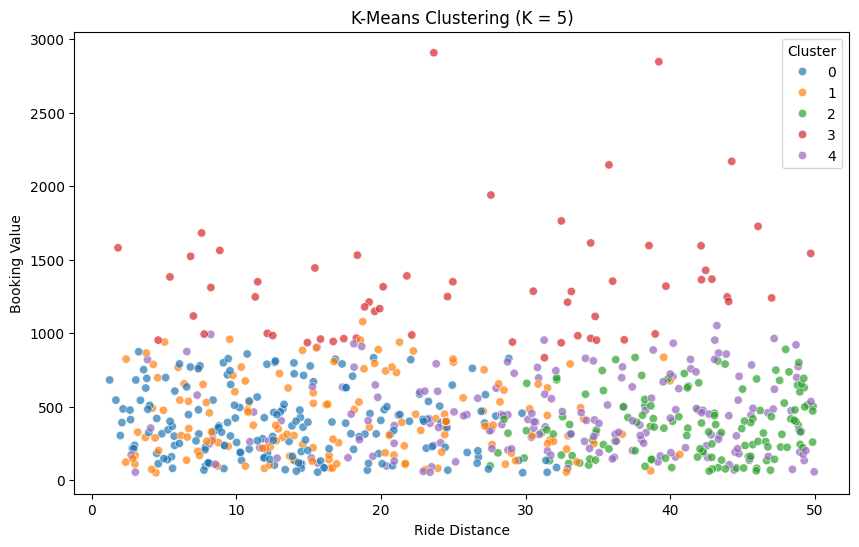

In [99]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clustered,
    x="Ride Distance",
    y="Booking Value",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("K-Means Clustering (K = 5)")
plt.xlabel("Ride Distance")
plt.ylabel("Booking Value")
plt.legend(title="Cluster")
plt.show()

KẾT LUẬN – K-Means Clustering (K = 5)
Biểu đồ Scatter Plot cho thấy thuật toán K-Means đã phân chia 1.000 chuyến xe thành 5 cụm với các đặc điểm khác nhau:
- Cụm 0 (xanh dương): Chủ yếu là chuyến ngắn, giá trị đặt xe thấp đến trung bình.
- Cụm 1 (cam): Chủ yếu là chuyến ngắn đến trung bình, có sự chồng lấn với cụm 0.
- Cụm 2 (xanh lá): Tập trung ở các chuyến dài, khoảng cách chủ yếu từ 30–50.
- Cụm 3 (đỏ): Nổi bật với giá trị đặt xe cao, nhiều chuyến vượt 1.000 và một số gần 3.000.
- Cụm 4 (tím): Chủ yếu là chuyến trung bình đến dài, giá trị đặt xe phân tán.
So What? K-Means đã nhận diện được các nhóm chuyến xe có sự khác biệt về khoảng cách và giá trị đặt xe. Tuy nhiên, một số cụm chồng lấn trên biểu đồ 2D.

Ảnh hưởng đến mô hình AI: Kết quả có thể hỗ trợ phân khúc chuyến xe và tạo đặc trưng Cluster cho các mô hình tiếp theo. Cần đánh giá thêm bằng Silhouette Score để xác định chất lượng phân cụm.

Đánh giá chất lượng phân cụm

In [100]:
from sklearn.metrics import silhouette_score

score = silhouette_score(
    X_scaled,
    cluster_labels
)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.1772


kết luận: phân cụm chưa tốt, thử lại từ K 2 - 10

,K,Silhouette Score
0,2,0.1966
1,3,0.1569
2,4,0.1653
3,5,0.1772
4,6,0.1732
5,7,0.1712
6,8,0.1768
7,9,0.1793
8,10,0.1343


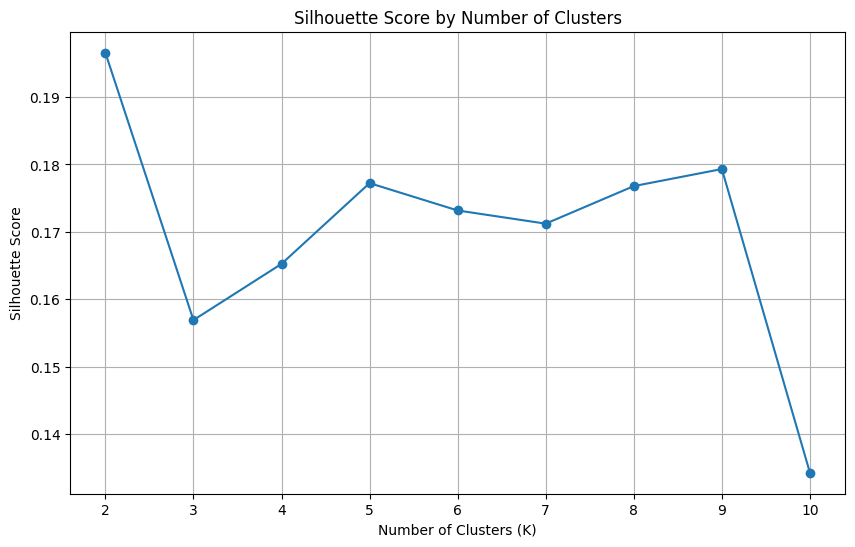

K có Silhouette Score cao nhất:


,K,Silhouette Score
0,2,0.196578


In [101]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    results.append({
        "K": k,
        "Silhouette Score": score
    })

df_scores = pd.DataFrame(results)

display(df_scores.round(4))

plt.figure(figsize=(10, 6))

plt.plot(
    df_scores["K"],
    df_scores["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

print("K có Silhouette Score cao nhất:")
display(df_scores.loc[[df_scores["Silhouette Score"].idxmax()]])

dù K = 2 là cao nhất, nhưng nó nằm ở mức 0.00 - 0.25 thì có thể chấp nhận được K = 5, vì K = 5 đã xem qua Elbow, nó nằm ở khúc khuỷu và lựa chọn nó để trực quan, phân tích.. Có thể là gần đúng với giá trị K = 2

**K-MEANS TRÊN DỮ LIỆU ĐÃ PCA**

In [102]:
df_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15
0,-1.462504,-0.620161,-0.469248,-0.051813,0.092988,0.899183,-0.578708,-2.335606,1.242089,1.976369,-0.310813,1.789444,-0.117776,-0.365857,1.031895
1,-1.434389,0.075346,2.509854,1.159022,0.905536,-0.350286,-0.914093,0.894501,0.426515,0.204970,0.056112,-0.723286,-0.163325,-1.407712,-0.354828
2,0.996758,2.988239,1.738034,-0.411480,-0.200860,-0.991366,1.669825,0.433839,1.327279,-0.701899,0.600922,2.671383,0.595093,0.954438,-0.763678
3,-1.193859,-0.774371,-0.038690,-0.833914,-1.192740,1.624591,0.203261,0.870333,-0.218958,-0.841982,1.315882,1.201642,0.156826,1.095546,-0.876620
4,0.096287,-0.445188,-0.444672,-0.381627,1.484048,1.276392,1.570226,-1.174271,0.303982,-0.671762,-0.788811,-1.795327,-0.736204,-0.072781,-0.402044


Kiểm tra dữ liệu PCA trước

In [103]:
print("Kích thước dữ liệu gốc:", X_scaled.shape)
print("Kích thước dữ liệu PCA:", df_pca.shape)

print("\nSố lượng giá trị NaN trong PCA:")
print(df_pca.isnull().sum())

print("\nKiểm tra các cột PCA:")
print(df_pca.columns.tolist())

Kích thước dữ liệu gốc: (1000, 11)
Kích thước dữ liệu PCA: (1000, 15)

Số lượng giá trị NaN trong PCA:
PC1     0
PC2     0
PC3     0
PC4     0
PC5     0
PC6     0
PC7     0
PC8     0
PC9     0
PC10    0
PC11    0
PC12    0
PC13    0
PC14    0
PC15    0
dtype: int64

Kiểm tra các cột PCA:
['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12', 'PC13', 'PC14', 'PC15']


Chạy K-Means trên dữ liệu PCA

In [104]:
from sklearn.cluster import KMeans

# Khởi tạo K-Means trên PCA
kmeans_pca = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Huấn luyện và phân cụm
labels_pca = kmeans_pca.fit_predict(df_pca)

# Tạo DataFrame kết quả
df_pca_clustered = df_pca.copy()

# Thêm nhãn cụm
df_pca_clustered["Cluster"] = labels_pca

# Hiển thị kết quả
display(df_pca_clustered.head())

# Thống kê số lượng phần tử trong mỗi cụm
print("Số lượng phần tử trong từng cụm:")
print(df_pca_clustered["Cluster"].value_counts().sort_index())

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,Cluster
0,-1.462504,-0.620161,-0.469248,-0.051813,0.092988,0.899183,-0.578708,-2.335606,1.242089,1.976369,-0.310813,1.789444,-0.117776,-0.365857,1.031895,0
1,-1.434389,0.075346,2.509854,1.159022,0.905536,-0.350286,-0.914093,0.894501,0.426515,0.204970,0.056112,-0.723286,-0.163325,-1.407712,-0.354828,4
2,0.996758,2.988239,1.738034,-0.411480,-0.200860,-0.991366,1.669825,0.433839,1.327279,-0.701899,0.600922,2.671383,0.595093,0.954438,-0.763678,3
3,-1.193859,-0.774371,-0.038690,-0.833914,-1.192740,1.624591,0.203261,0.870333,-0.218958,-0.841982,1.315882,1.201642,0.156826,1.095546,-0.876620,4
4,0.096287,-0.445188,-0.444672,-0.381627,1.484048,1.276392,1.570226,-1.174271,0.303982,-0.671762,-0.788811,-1.795327,-0.736204,-0.072781,-0.402044,4


Số lượng phần tử trong từng cụm:
Cluster
0     60
1    161
2     57
3    136
4    586
Name: count, dtype: int64


Kết luận: Cụm 4 chiếm tỷ lệ lớn nhất (58,6%), trong khi cụm 2 nhỏ nhất (5,7%). Dữ liệu phân bố không đồng đều giữa các cụm. Tuy nhiên, chưa thể đánh giá chất lượng phân cụm chỉ dựa trên số lượng phần tử.

Kiểm tra Silhouette Score

In [105]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

results_pca = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(df_pca)

    score = silhouette_score(df_pca, labels)

    results_pca.append({
        "K": k,
        "Silhouette Score": score
    })

# Tạo bảng kết quả
df_scores_pca = pd.DataFrame(results_pca)

display(df_scores_pca.round(4))

# Tìm K có Silhouette cao nhất
best_row = df_scores_pca.loc[
    df_scores_pca["Silhouette Score"].idxmax()
]

print("K tốt nhất:", int(best_row["K"]))
print("Silhouette Score cao nhất:", round(best_row["Silhouette Score"], 4))

,K,Silhouette Score
0,2,0.1686
1,3,0.1933
2,4,0.1500
3,5,0.2182
4,6,0.1954
5,7,0.2501
6,8,0.2666
7,9,0.2780
8,10,0.2441


K tốt nhất: 9
Silhouette Score cao nhất: 0.278


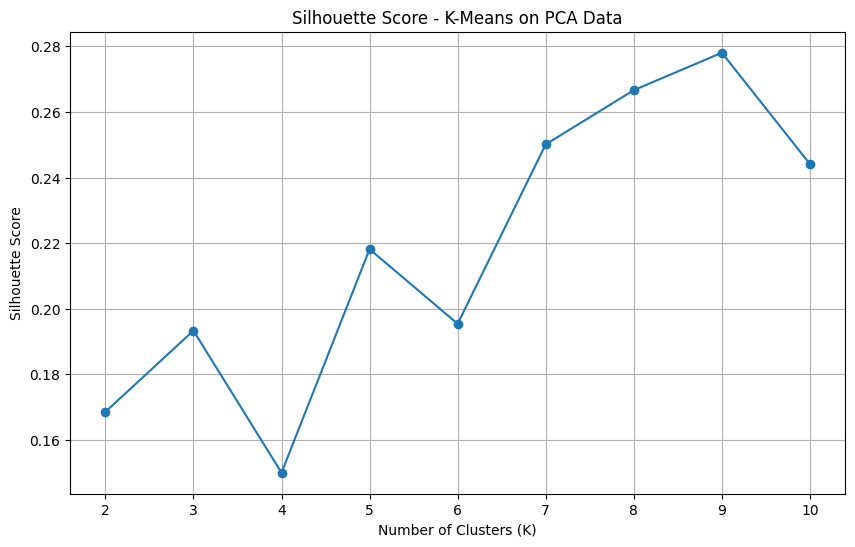

In [106]:
plt.figure(figsize=(10, 6))

plt.plot(
    df_scores_pca["K"],
    df_scores_pca["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score - K-Means on PCA Data")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

K = 9: Đạt Silhouette Score cao nhất, khoảng 0.278, cho thấy khả năng phân tách cụm tốt nhất trong các giá trị đã thử.

Lập bảng đối chiếu

In [107]:
comparison = pd.DataFrame({
    "Phuong_phap": [
        "K-Means goc",
        "K-Means goc",
        "K-Means PCA",
        "K-Means PCA"
    ],
    "K": [2, 5, 5, 9],
    "Silhouette_Score": [
        0.196578,
        0.1772,
        df_scores_pca.loc[
            df_scores_pca["K"] == 5, "Silhouette Score"
        ].iloc[0],
        df_scores_pca.loc[
            df_scores_pca["K"] == 9, "Silhouette Score"
        ].iloc[0]
    ]
})

display(comparison.round(4))

,Phuong_phap,K,Silhouette_Score
0,K-Means goc,2,0.1966
1,K-Means goc,5,0.1772
2,K-Means PCA,5,0.2182
3,K-Means PCA,9,0.2780


KẾT LUẬN
- Với cùng K = 5, K-Means PCA đạt 0.2182, cao hơn K-Means gốc (0.1772).
- K-Means PCA với K = 9 đạt điểm cao nhất (0.2780).
- Tuy nhiên, tất cả điểm Silhouette đều dưới 0.3, cho thấy các cụm vẫn chưa được phân tách rõ ràng.
So What? K-Means trên dữ liệu PCA hiện có kết quả Silhouette tốt hơn, nhưng chưa thể khẳng định PCA là nguyên nhân vì dữ liệu gốc sử dụng 11 đặc trưng còn df_pca có 15 thành phần chính.

Biểu đồ phân cụm 2D/3D

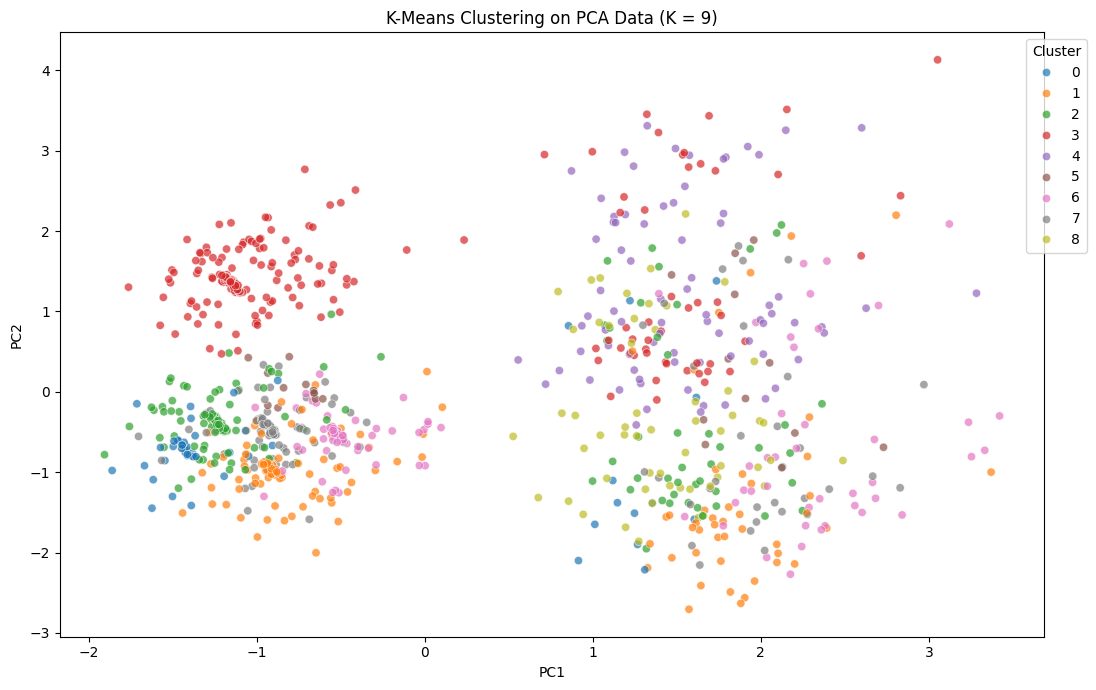

In [108]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# Chạy K-Means trên PCA với K = 9
kmeans_pca_9 = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

labels_pca_9 = kmeans_pca_9.fit_predict(df_pca)

# Tạo DataFrame riêng
df_pca_9 = df_pca.copy()
df_pca_9["Cluster"] = labels_pca_9

# Vẽ biểu đồ
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df_pca_9,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("K-Means Clustering on PCA Data (K = 9)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

Biểu đồ cho thấy thuật toán K-Means đã phân chia 1.000 chuyến xe thành 9 cụm trên dữ liệu PCA.
- Các điểm dữ liệu hình thành hai vùng tập trung chính theo trục PC1.
- Cụm 3 (đỏ) khá nổi bật ở vùng phía trên bên trái, cho thấy khả năng phân tách tương đối rõ trên hình chiếu 2D.
- Những cụm còn lại có hiện tượng chồng lấn, đặc biệt ở vùng bên phải.
- Silhouette Score = 0.2780, cho thấy chất lượng phân cụm còn hạn chế, dù cao hơn các kết quả K-Means gốc đã thử.
So What?
PCA kết hợp K-Means giúp trực quan hóa các nhóm chuyến xe theo các thành phần chính. Tuy nhiên, sự chồng lấn giữa nhiều cụm cho thấy khả năng phân biệt các nhóm vẫn chưa thực sự rõ ràng.

kiểm tra lại dữ liệu, xem có đúng đắn không.

In [109]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

# Chuẩn hóa lại đúng bộ đặc trưng dùng tạo PCA
X_original_compare = StandardScaler().fit_transform(X)

# Kiểm tra dữ liệu và thứ tự dòng có khớp PCA không
print("Trước PCA:", X_original_compare.shape)
print("Sau PCA:", df_pca.shape)

# Kiểm tra tính nhất quán với PCA đã huấn luyện
print(
    "PCA khớp dữ liệu:",
    np.allclose(
        pca.transform(X_original_compare),
        df_pca.to_numpy()
    )
)

# K-Means trước PCA, K = 5
model_original = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

labels_original = model_original.fit_predict(X_original_compare)

score_original = silhouette_score(
    X_original_compare,
    labels_original
)

# K-Means sau PCA, K = 5
model_pca = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

labels_pca_compare = model_pca.fit_predict(df_pca)

score_pca = silhouette_score(
    df_pca,
    labels_pca_compare
)

print("Silhouette gốc:", round(score_original, 4))
print("Silhouette PCA:", round(score_pca, 4))

Trước PCA: (1000, 19)
Sau PCA: (1000, 15)
PCA khớp dữ liệu: True
Silhouette gốc: 0.1844
Silhouette PCA: 0.2182


K-Means lại trên biểu đổ PCA/Gốc

,K,Original,PCA
0,2,0.1639,0.1686
1,3,0.1685,0.1933
2,4,0.1928,0.1500
3,5,0.1844,0.2182
4,6,0.1921,0.1954
5,7,0.2157,0.2501
6,8,0.2479,0.2666
7,9,0.2588,0.2780
8,10,0.2619,0.2441


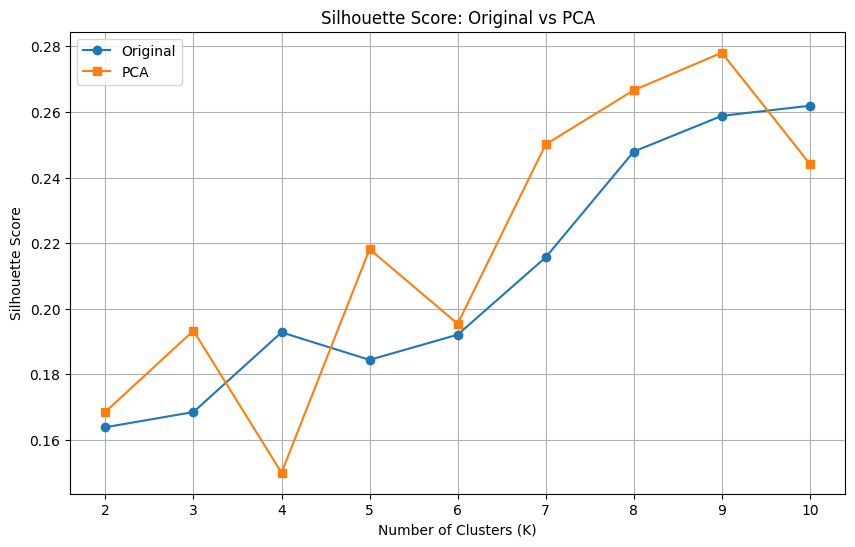

In [110]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

results_compare = []

for k in range(2, 11):
    # K-Means trên dữ liệu gốc
    model_original = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_original = model_original.fit_predict(
        X_original_compare
    )

    score_original = silhouette_score(
        X_original_compare,
        labels_original
    )

    # K-Means trên dữ liệu PCA
    model_pca = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_pca = model_pca.fit_predict(df_pca)

    score_pca = silhouette_score(
        df_pca,
        labels_pca
    )

    results_compare.append({
        "K": k,
        "Original": score_original,
        "PCA": score_pca
    })

# Bảng so sánh
df_compare = pd.DataFrame(results_compare)

display(df_compare.round(4))

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))

plt.plot(
    df_compare["K"],
    df_compare["Original"],
    marker="o",
    label="Original"
)

plt.plot(
    df_compare["K"],
    df_compare["PCA"],
    marker="s",
    label="PCA"
)

plt.title("Silhouette Score: Original vs PCA")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.legend()
plt.grid(True)
plt.show()

Kết quả đánh giá cho thấy K-Means sau PCA đạt Silhouette Score cao nhất là 0.2780 tại K = 9, trong khi K-Means gốc đạt cao nhất 0.2619 tại K = 10. PCA cho kết quả tốt hơn ở 7/9 giá trị K, cho thấy lợi ích nhất định của việc giảm chiều. Tuy nhiên, chất lượng phân cụm vẫn chưa cao. Vì vậy, K-Means PCA với K = 9 được đề xuất dựa trên chỉ số Silhouette, nhưng cần đánh giá thêm khả năng diễn giải đặc điểm từng cụm trước khi lựa chọn cuối cùng.

In [111]:
# Gắn nhãn cụm PCA K=9 vào dữ liệu gốc
df_pca_result = df_clean.copy()
df_pca_result["Cluster_PCA"] = labels_pca_9

# Thống kê đặc điểm từng cụm
pca_summary = df_pca_result.groupby("Cluster_PCA").agg(
    Number_of_Rides=("Booking ID", "count"),
    Avg_Ride_Distance=("Ride Distance", "mean"),
    Avg_Booking_Value=("Booking Value", "mean"),
    Avg_VTAT=("Avg VTAT", "mean"),
    Avg_CTAT=("Avg CTAT", "mean"),
    Avg_Driver_Rating=("Driver Ratings", "mean"),
    Avg_Customer_Rating=("Customer Rating", "mean")
)

display(pca_summary.round(2))

,Number_of_Rides,Avg_Ride_Distance,Avg_Booking_Value,Avg_VTAT,Avg_CTAT,Avg_Driver_Rating,Avg_Customer_Rating
Cluster_PCA,,,,,,,
0,60,25.53,440.03,8.09,28.74,4.21,4.49
1,159,25.58,484.07,8.51,28.75,4.26,4.47
2,167,24.69,436.10,8.27,28.28,4.30,4.43
3,224,23.80,453.38,8.51,28.60,4.26,4.41
4,78,24.28,514.10,8.15,28.07,4.23,4.39
5,24,21.14,451.08,7.48,24.75,4.25,4.54
6,119,27.14,464.14,8.40,28.04,4.23,4.44
7,113,26.55,455.79,8.04,29.72,4.26,4.44
8,56,26.47,398.86,8.19,28.31,4.18,4.47


xem 9 cụm khác nhau như thế nào về loại phương tiện và phương thức thanh toán

In [112]:
for col in ["Vehicle Type", "Payment Method"]:
    print(f"\nPhân bố {col} theo cụm (%):")

    table = pd.crosstab(
        df_pca_result["Cluster_PCA"],
        df_pca_result[col],
        normalize="index"
    ) * 100

    display(table.round(2))


Phân bố Vehicle Type theo cụm (%):


Vehicle Type,Auto,Bike,Go Mini,Go Sedan,Premier Sedan,Uber XL,eBike
Cluster_PCA,,,,,,,
0,0.00,0.00,0.00,0.00,0.00,0.0,100.00
1,0.00,0.00,100.00,0.00,0.00,0.0,0.00
2,0.00,0.00,0.00,100.00,0.00,0.0,0.00
3,100.00,0.00,0.00,0.00,0.00,0.0,0.00
4,34.62,16.67,19.23,12.82,16.67,0.0,0.00
5,0.00,0.00,0.00,0.00,0.00,100.0,0.00
6,0.00,100.00,0.00,0.00,0.00,0.0,0.00
7,0.00,0.00,0.00,0.00,100.00,0.0,0.00
8,26.79,25.00,23.21,12.50,10.71,0.0,1.79



Phân bố Payment Method theo cụm (%):


Payment Method,Cash,Credit Card,Debit Card,UPI,Uber Wallet
Cluster_PCA,,,,,
0,16.67,0.00,1.67,76.67,5.00
1,23.90,0.00,3.77,72.33,0.00
2,17.96,0.00,7.78,74.25,0.00
3,14.73,0.00,7.14,78.12,0.00
4,0.00,0.00,0.00,0.00,100.00
5,25.00,4.17,0.00,50.00,20.83
6,26.05,0.00,8.40,65.55,0.00
7,20.35,0.00,7.08,72.57,0.00
8,0.00,100.00,0.00,0.00,0.00


**KẾT LUẬN CUỐI CÙNG:** K-Means sau PCA với K = 9 đạt Silhouette Score cao nhất (0.2780), nhỉnh hơn K-Means gốc (0.2619). Các cụm PCA có khả năng diễn giải rõ ràng theo loại phương tiện và phương thức thanh toán, với 7 cụm đại diện cho từng loại xe và 2 cụm đại diện cho phương thức thanh toán. Tuy nhiên, sự khác biệt giữa các cụm về khoảng cách, giá trị đặt xe và thời gian không lớn. Vì vậy, K-Means PCA là phương án phù hợp hơn theo chỉ số Silhouette trong thử nghiệm hiện tại, nhưng chưa chứng minh được khả năng phân khúc hành vi chuyến xe tốt hơn.